In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
plt.style.use('seaborn-v0_8-whitegrid')

import xgboost as xgb

这里的特征工程策略基于 Boosting 思想  
逐层增加模型复杂度，用模型表现的变化来推断数据中存在哪种特征关系

用 Stumps（深度=1 的决策树）作为基线模型
- 每棵树只能根据单个特征进行一次划分，所以模型只能学习单变量与目标变量的关系
- 可以通过观察特征重要性来发现最关键的单个特征，然后尝试单个特征的转换，如 `e^x, log(x), x^2, x^3, tanh(x)`

用 2-level 树（深度=2）来检测特征交互
- 深度=2 意味着模型可以根据一个特征再在某个子区域用另一个特征做划分
- 这样模型可以捕捉两个特征之间的交互效应
- 比较 validation error 是否比深度=1 时显著下降；如果显著下降，说明特征交互很重要
- 可以计算 SHAP 值和 sumnmary plot 来发现究竟是哪些特征有这种交互效应

In [2]:
train = (
    pd.read_csv("../Datasets/train.csv")
    .rename(columns={"market_forward_excess_returns": "target"})
)

# Cast all columns except 'date_id' to float
cols_to_cast = [c for c in train.columns if c != "date_id"]
train[cols_to_cast] = train[cols_to_cast].astype(float)

train

,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V3,V4,V5,V6,V7,V8,V9,forward_returns,risk_free_rate,target
0,0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.002421,0.000301,-0.003038
1,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.008495,0.000303,-0.009114
2,2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.009624,0.000301,-0.010243
3,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.004662,0.000299,0.004046
4,4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.011686,0.000299,-0.012301
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9016,9016,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.208995,0.484788,0.717308,0.677249,-0.327455,0.083995,-0.380452,-0.000015,0.000151,-0.000477
9017,9017,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.082011,0.482804,1.001028,0.596561,-0.372979,0.094246,-0.427355,-0.005199,0.000150,-0.005661
9018,9018,0.0,0.0,0.0,1.0,0.0,-1.0,0.0,0.0,0.0,...,0.334656,0.486772,0.894502,0.656746,-0.282024,0.090608,-0.381337,0.005930,0.000150,0.005467
9019,9019,0.0,0.0,0.0,1.0,0.0,-1.0,0.0,0.0,0.0,...,0.163360,0.492725,1.117639,0.674603,-0.445261,0.106481,-0.477635,0.008173,0.000150,0.007710


## Create Feature DataFrame

Note that the New York Fed publishes the EFFR for the **prior** business day on the New York Fed’s website at approximately 9:00 a.m., so we need to shift 1 by one day to avoid look-ahead bias.

In [3]:
feature_df = train.copy()

M_cols = [c for c in feature_df.columns if c.startswith('M')]
E_cols = [c for c in feature_df.columns if c.startswith('E')]
I_cols = [c for c in feature_df.columns if c.startswith('I')]
P_cols = [c for c in feature_df.columns if c.startswith('P')]
V_cols = [c for c in feature_df.columns if c.startswith('V')]
S_cols = [c for c in feature_df.columns if c.startswith('S')]
D_cols = [c for c in feature_df.columns if c.startswith('D')]

groups = {
    "Market Dynamics (M*)": M_cols,
    "Macro Economic (E*)": E_cols,
    "Interest Rate (I*)": I_cols,
    "Price/Valuation (P*)": P_cols,
    "Volatility (V*)": V_cols,
    "Sentiment (S*)": S_cols,
    "Dummy/Binary (D*)": D_cols
}


feature_df['lagged_risk_free_rate'] = feature_df['risk_free_rate'].shift(1)
feature_df['lagged_forward_returns'] = feature_df['forward_returns'].shift(1)
feature_df['lagged_target'] = feature_df['target'].shift(1)

anonymous_features = M_cols + E_cols + I_cols + P_cols + V_cols + S_cols + D_cols
lagged_features = ['lagged_risk_free_rate', 'lagged_forward_returns', 'lagged_target']

features = anonymous_features + lagged_features

print('Number of features to investigate: {}'.format(len(features)))
print('\nTop 20 NaN counts:')
print(feature_df.isna().sum().sort_values(ascending=False).head(20))

Number of features to investigate: 97

Top 20 NaN counts:
E7     6969
V10    6049
S3     5733
M1     5547
M13    5540
M14    5540
M6     5043
V9     4539
S12    3537
M5     3283
M2     3217
S8     3009
M3     2018
E1     1784
P6     1638
P7     1616
E20    1616
P5     1574
V5     1512
S5     1511
dtype: int64


## Day Forward-Chaining Nested Cross Validation
队友提到了这种模型驱动的特征工程方法有数据窥探的风险，于是想了用 nested CV 尽可能的避免这个问题
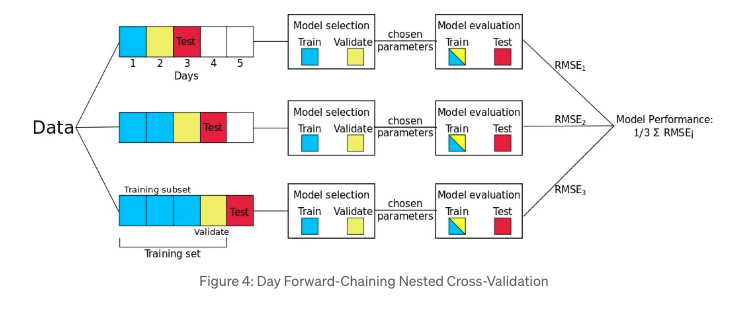

In [4]:
DATES = feature_df['date_id'].unique()
START_DATE_ID = int(DATES[0])
print('Start date_id:', START_DATE_ID)
END_DATE_ID = int(DATES[-1])
print('End date_id:', END_DATE_ID)
N_DATES = END_DATE_ID - START_DATE_ID + 1
print('Total number of trading days in the feature DataFrame:', N_DATES)

Start date_id: 0
End date_id: 9020
Total number of trading days in the feature DataFrame: 9021


In [5]:
PURGE = 5
OUTER_TRAIN_SIZE = 252 * 5  # 5 years
OUTER_TEST_SIZE = 126  # 6 months
INNER_FOLDS = 5
INNER_TRAIN_SIZE = 252 * 3 # 3 year
INNER_VAL_SIZE = OUTER_TEST_SIZE  # 6 months

# OUTER LOOP
OUTER_FOLDS = ((N_DATES - OUTER_TRAIN_SIZE - PURGE - OUTER_TEST_SIZE) // OUTER_TEST_SIZE) + 1
print("Number of Outer Folds:", OUTER_FOLDS)

for outer_i in range(OUTER_FOLDS):
    outer_train_start = START_DATE_ID + outer_i * OUTER_TEST_SIZE
    outer_train_end = outer_train_start + OUTER_TRAIN_SIZE - 1
    outer_test_start = outer_train_end + PURGE + 1
    if outer_i == OUTER_FOLDS - 1:
        outer_test_end = END_DATE_ID
    else:
        outer_test_end = outer_test_start + OUTER_TEST_SIZE - 1

    print(
        f"\nOuter Fold {outer_i+1}: "
        f"Train {outer_train_start}–{outer_train_end} "
        f"(len={outer_train_end - outer_train_start + 1}) | "
        f"Test {outer_test_start}–{outer_test_end} "
        f"(len={outer_test_end - outer_test_start + 1})"
    )

    # INNER SPLITS
    outer_train_len = outer_train_end - outer_train_start + 1
    STEP = 93

    for inner_i in range(INNER_FOLDS):
        # rolling inner training window
        inner_train_start = outer_train_start + inner_i * STEP
        inner_train_end = inner_train_start + INNER_TRAIN_SIZE - 1

        # validation window right after train
        inner_val_start = inner_train_end + PURGE + 1
        inner_val_end = inner_val_start + INNER_VAL_SIZE - 1

        # adjust last inner fold to hit outer_train_end exactly
        if inner_i == INNER_FOLDS - 1:
            inner_val_end = outer_train_end
            inner_val_start = inner_val_end - INNER_VAL_SIZE + 1
            inner_train_end = inner_val_start - PURGE - 1
            inner_train_start = inner_train_end - INNER_TRAIN_SIZE + 1

        print(f"  Inner Fold {inner_i+1}: "
              f"Train {inner_train_start}–{inner_train_end} (len={inner_train_end - inner_train_start + 1})"
              f" | Val {inner_val_start}–{inner_val_end} (len={inner_val_end - inner_val_start + 1})")

Number of Outer Folds: 61

Outer Fold 1: Train 0–1259 (len=1260) | Test 1265–1390 (len=126)
  Inner Fold 1: Train 0–755 (len=756) | Val 761–886 (len=126)
  Inner Fold 2: Train 93–848 (len=756) | Val 854–979 (len=126)
  Inner Fold 3: Train 186–941 (len=756) | Val 947–1072 (len=126)
  Inner Fold 4: Train 279–1034 (len=756) | Val 1040–1165 (len=126)
  Inner Fold 5: Train 373–1128 (len=756) | Val 1134–1259 (len=126)

Outer Fold 2: Train 126–1385 (len=1260) | Test 1391–1516 (len=126)
  Inner Fold 1: Train 126–881 (len=756) | Val 887–1012 (len=126)
  Inner Fold 2: Train 219–974 (len=756) | Val 980–1105 (len=126)
  Inner Fold 3: Train 312–1067 (len=756) | Val 1073–1198 (len=126)
  Inner Fold 4: Train 405–1160 (len=756) | Val 1166–1291 (len=126)
  Inner Fold 5: Train 499–1254 (len=756) | Val 1260–1385 (len=126)

Outer Fold 3: Train 252–1511 (len=1260) | Test 1517–1642 (len=126)
  Inner Fold 1: Train 252–1007 (len=756) | Val 1013–1138 (len=126)
  Inner Fold 2: Train 345–1100 (len=756) | Val 110

In [6]:
def get_day_forward_chaining_nested_cv(
    dates, purge, outer_train_size, outer_test_size, 
    inner_folds, inner_train_size, inner_val_size, step
):
    """
    Generates indices for Day Forward-Chaining Nested CV
    """
    
    start_date_id = int(dates[0])
    end_date_id = int(dates[-1])
    n_dates = end_date_id - start_date_id + 1

    # OUTER LOOP
    outer_folds_count = ((n_dates - outer_train_size - purge - outer_test_size) // outer_test_size) + 1
    
    for outer_i in range(outer_folds_count):
        outer_train_start = start_date_id + outer_i * outer_test_size
        outer_train_end = outer_train_start + outer_train_size - 1
        outer_test_start = outer_train_end + purge + 1
        
        if outer_i == outer_folds_count - 1:
            outer_test_end = end_date_id
        else:
            outer_test_end = outer_test_start + outer_test_size - 1

        outer_train_idx = (outer_train_start, outer_train_end)
        outer_test_idx = (outer_test_start, outer_test_end)
        
        # INNER SPLITS
        inner_splits = []

        for inner_i in range(inner_folds):
            inner_train_start = outer_train_start + inner_i * step
            inner_train_end = inner_train_start + inner_train_size - 1
            inner_val_start = inner_train_end + purge + 1
            inner_val_end = inner_val_start + inner_val_size - 1

            # Adjust last inner fold to hit outer_train_end exactly
            if inner_i == inner_folds - 1:
                inner_val_end = outer_train_end
                inner_val_start = inner_val_end - inner_val_size + 1
                inner_train_end = inner_val_start - purge - 1
                inner_train_start = inner_train_end - inner_train_size + 1

            inner_train_idx = (int(inner_train_start), int(inner_train_end))
            inner_val_idx = (int(inner_val_start), int(inner_val_end))
            inner_splits.append((inner_train_idx, inner_val_idx))
            
        yield outer_train_idx, outer_test_idx, inner_splits

In [7]:
# Initialize the generator
cv_generator = get_day_forward_chaining_nested_cv(
    dates=DATES,
    purge=PURGE,
    outer_train_size=OUTER_TRAIN_SIZE,
    outer_test_size=OUTER_TEST_SIZE,
    inner_folds=INNER_FOLDS,
    inner_train_size=INNER_TRAIN_SIZE,
    inner_val_size=INNER_VAL_SIZE,
    step=93
)

In [8]:
from scoring_metric import score, ParticipantVisibleError
print('Competition metric imported successfully!')

Competition metric imported successfully!


In [9]:
PARAMS = {
    'n_estimators': 500,
    'max_depth': 1,
    'learning_rate': 0.05,
    'n_jobs': -1,
    'random_state': 42
}

In [10]:
def run_day_forward_chaining_nested_cv(
    feature_df, features, cv_generator, model, params, signal_multiplier=20, verbose=True
):
    outer_scores = []
    inner_scores_dict = {}
    outer_models = []
    outer_X_tests = []

    for outer_i, (outer_train_idx, outer_test_idx, inner_splits) in enumerate(cv_generator):
        if verbose:
            print(f"\n===== OUTER FOLD {outer_i + 1} =====")

        # Masking
        outer_train_mask = (feature_df['date_id'].between(outer_train_idx[0], outer_train_idx[1]))
        outer_test_mask  = (feature_df['date_id'].between(outer_test_idx[0],  outer_test_idx[1]))

        X_train_outer = feature_df.loc[outer_train_mask, features]
        y_train_outer = feature_df.loc[outer_train_mask, 'target']
        X_test_outer  = feature_df.loc[outer_test_mask,  features]
        solution_outer = feature_df.loc[outer_test_mask, ['forward_returns', 'risk_free_rate']].copy()
        outer_X_tests.append(X_test_outer.copy())
        print(f"X_train_outer: {X_train_outer.shape}, X_test_outer: {X_test_outer.shape}")


        inner_fold_scores = []

        for inner_j, (inner_train_idx, inner_val_idx) in enumerate(inner_splits):
            inner_train_mask = feature_df['date_id'].between(inner_train_idx[0], inner_train_idx[1])
            inner_val_mask   = feature_df['date_id'].between(inner_val_idx[0], inner_val_idx[1])

            X_train_inner = feature_df.loc[inner_train_mask, features]
            y_train_inner = feature_df.loc[inner_train_mask, 'target']
            X_val_inner   = feature_df.loc[inner_val_mask, features]
            solution_inner = feature_df.loc[inner_val_mask, ['forward_returns', 'risk_free_rate']].copy()
            print(f"X_train_inner: {X_train_inner.shape}, X_val_inner : {X_val_inner.shape}")

            model_inner = model(**params)
            model_inner.fit(X_train_inner, y_train_inner)

            preds_inner = model_inner.predict(X_val_inner)
            position_inner = np.clip(preds_inner * signal_multiplier + 1, 0, 2)
            submission_inner = pd.DataFrame({'prediction': position_inner}, index=X_val_inner.index)
            assert submission_inner.index.equals(X_val_inner.index)
            assert len(submission_inner) == len(solution_inner)
            print(f"\nInner Fold {inner_j + 1} Submission DataFrame (first 5 rows):")
            print(submission_inner.head())

            inner_score = score(solution_inner, submission_inner, 'index')
            inner_fold_scores.append(inner_score)

        inner_scores_dict[outer_i + 1] = inner_fold_scores
        mean_inner_score = np.mean(inner_fold_scores)
        print(f" Mean Inner Sharpe (Outer {outer_i + 1}): {mean_inner_score:.4f}")

        # Outer fit
        model_outer = model(**params)
        model_outer.fit(X_train_outer, y_train_outer)
        outer_models.append(model_outer)

        preds_outer = model_outer.predict(X_test_outer)
        position_outer = np.clip(preds_outer * signal_multiplier + 1, 0, 2)
        submission_outer = pd.DataFrame({'prediction': position_outer}, index=X_test_outer.index)
        assert submission_outer.index.equals(X_test_outer.index)
        assert len(submission_outer) == len(solution_outer)
        print(f"\nOuter Fold {outer_i + 1} Submission DataFrame (first 5 rows):")
        print(submission_outer.head())

        outer_score = score(solution_outer, submission_outer, 'index')
        outer_scores.append(outer_score)

        if verbose:
            print(f"  Outer Fold {outer_i + 1} Adjusted Sharpe: {outer_score:.4f}")

    print('\nAverage Outer Folds Score:', np.mean(outer_scores))

    return {
        'outer_scores': outer_scores,
        'inner_scores_dict': inner_scores_dict,
        'outer_models': outer_models,
        'outer_X_tests': outer_X_tests
    }

In [11]:
results = run_day_forward_chaining_nested_cv(feature_df, features, cv_generator, xgb.XGBRegressor, PARAMS)


===== OUTER FOLD 1 =====
X_train_outer: (1260, 97), X_test_outer: (126, 97)
X_train_inner: (756, 97), X_val_inner : (126, 97)

Inner Fold 1 Submission DataFrame (first 5 rows):
     prediction
761    0.989070
762    0.989070
763    0.988071
764    0.993376
765    0.993376
X_train_inner: (756, 97), X_val_inner : (126, 97)

Inner Fold 2 Submission DataFrame (first 5 rows):
     prediction
854    0.996336
855    1.071564
856    0.996336
857    1.005560
858    0.996336
X_train_inner: (756, 97), X_val_inner : (126, 97)

Inner Fold 3 Submission DataFrame (first 5 rows):
     prediction
947    1.036463
948    1.029549
949    0.988608
950    0.987492
951    0.987492
X_train_inner: (756, 97), X_val_inner : (126, 97)

Inner Fold 4 Submission DataFrame (first 5 rows):
      prediction
1040    1.075755
1041    1.155833
1042    1.122328
1043    1.117438
1044    0.988618
X_train_inner: (756, 97), X_val_inner : (126, 97)

Inner Fold 5 Submission DataFrame (first 5 rows):
      prediction
1134    1.2

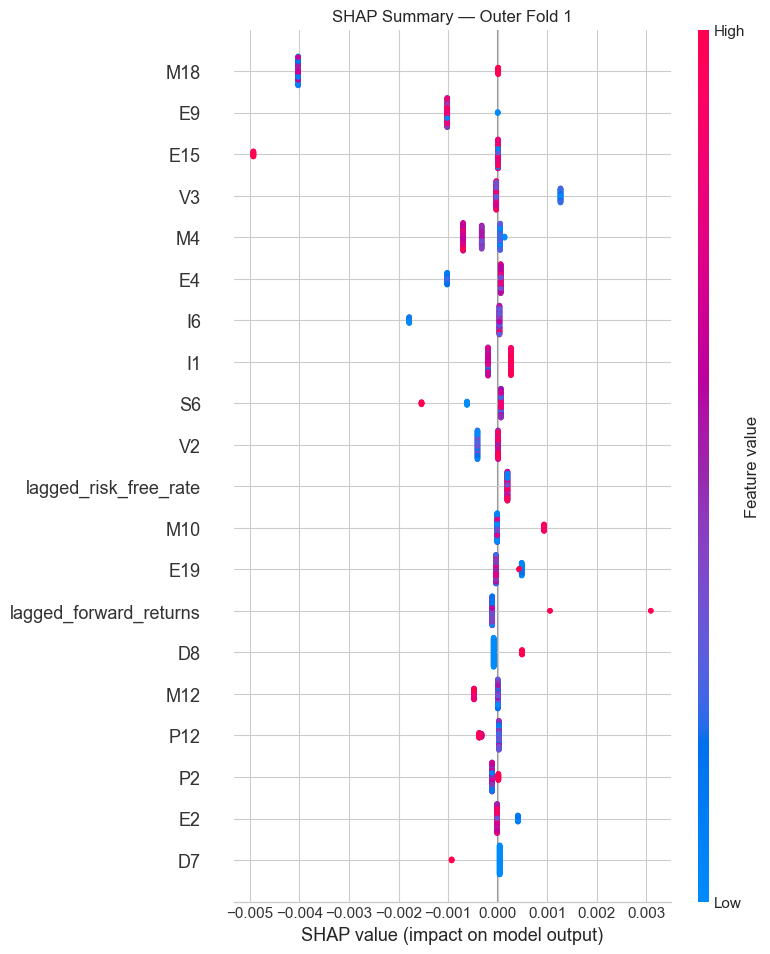

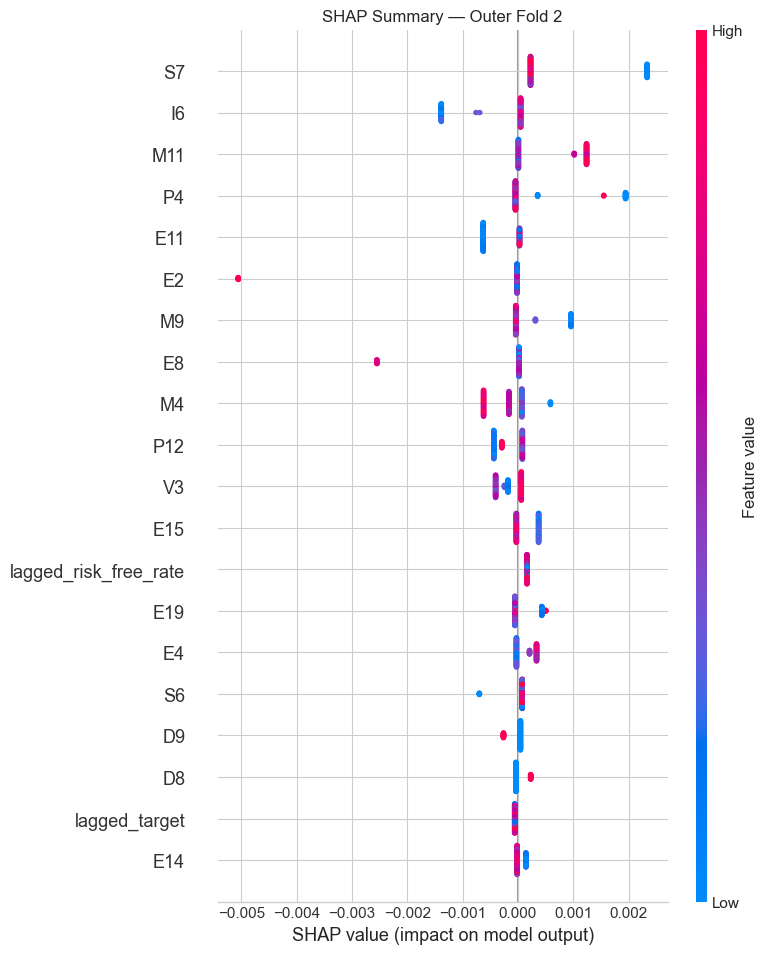

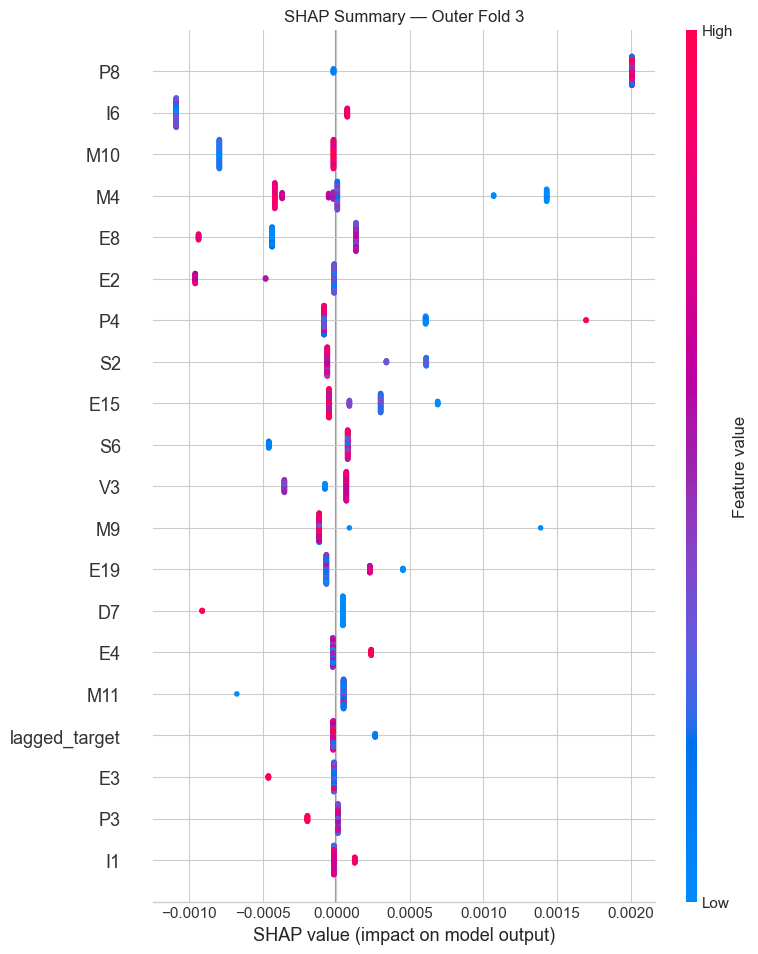

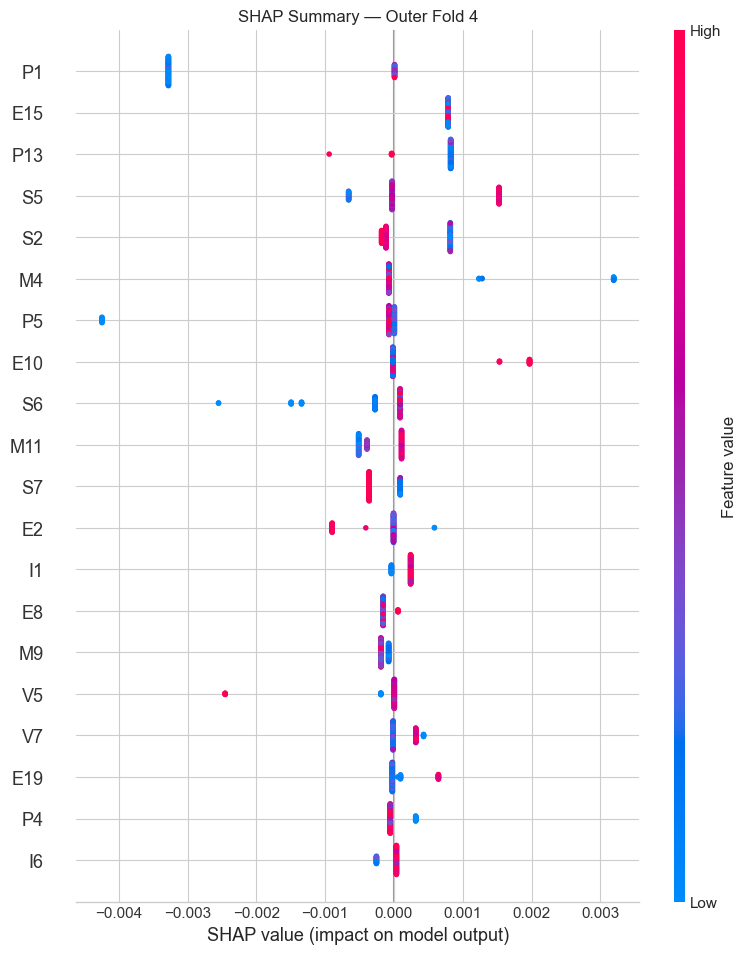

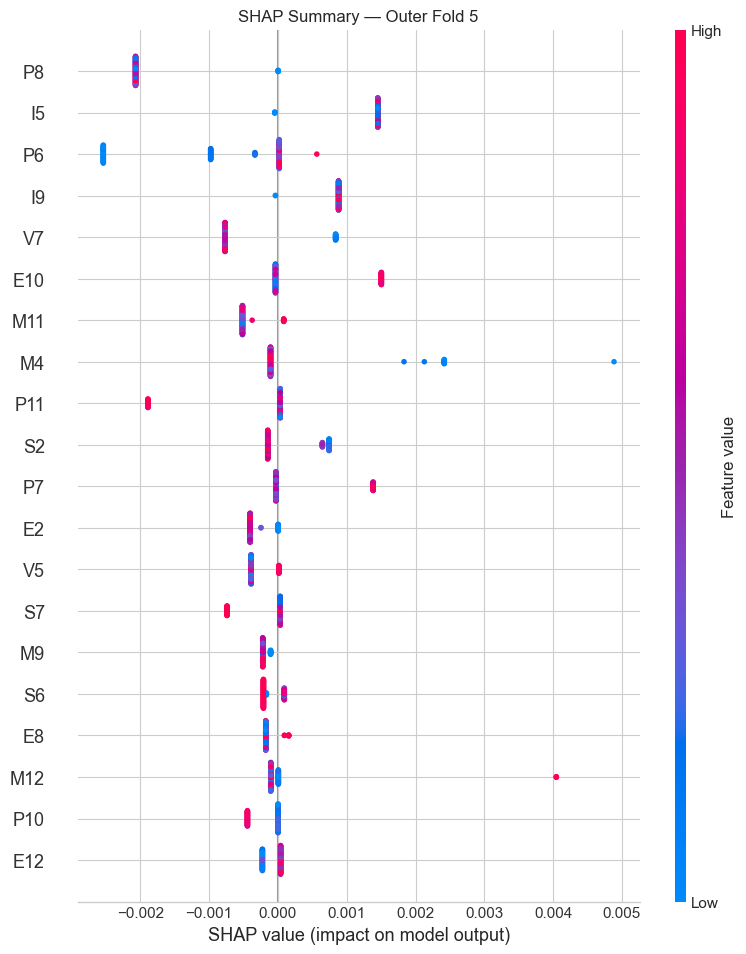

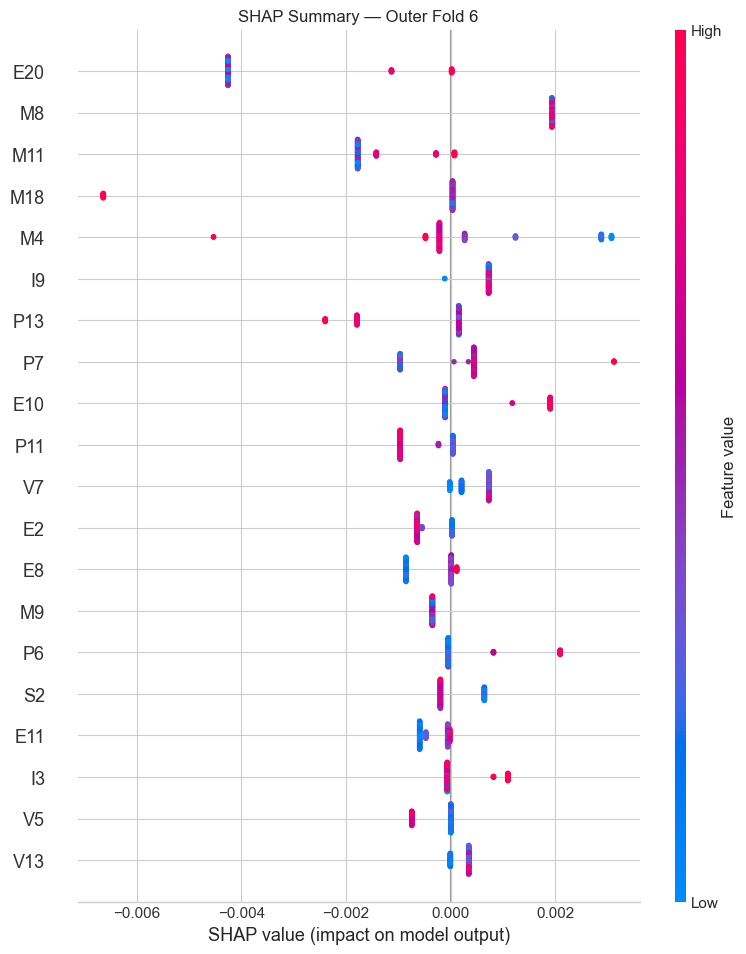

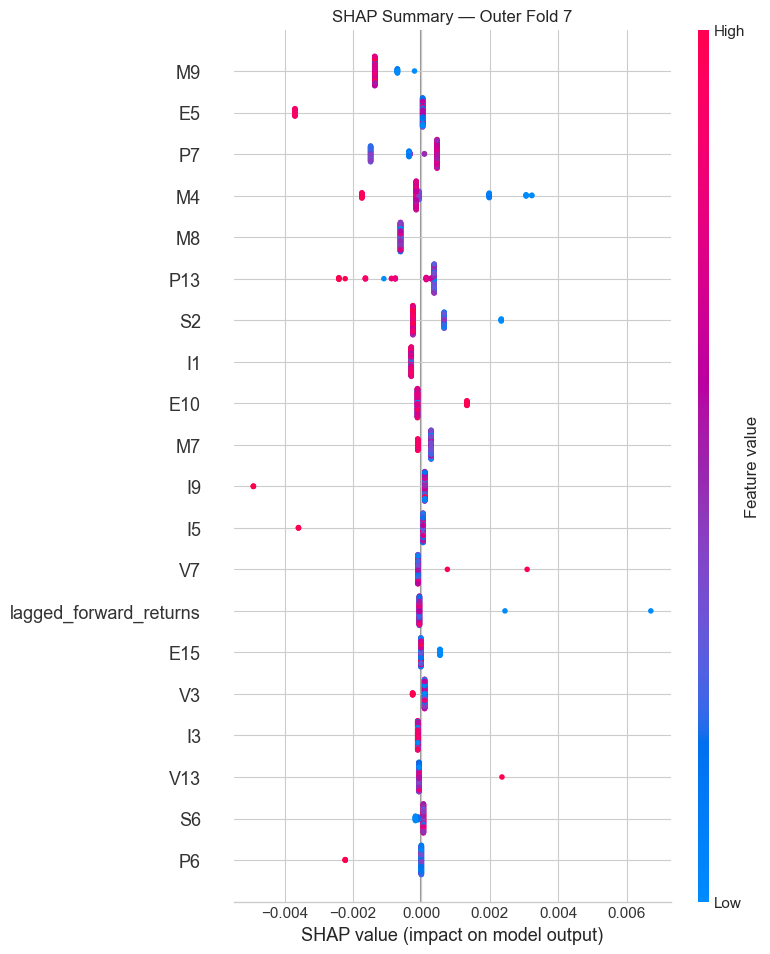

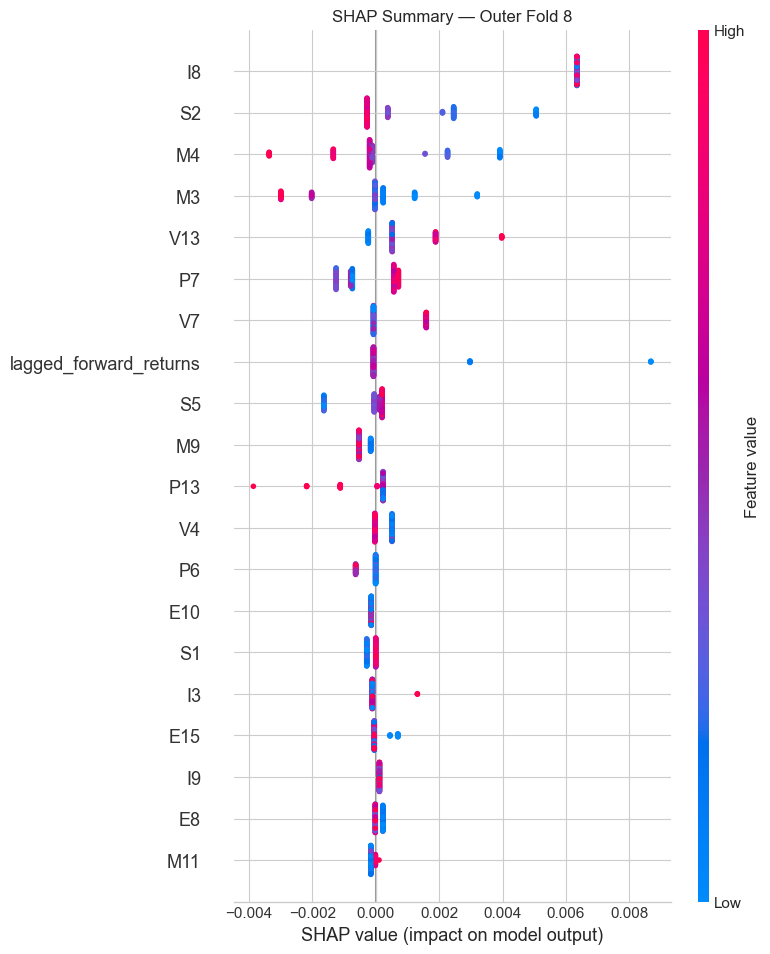

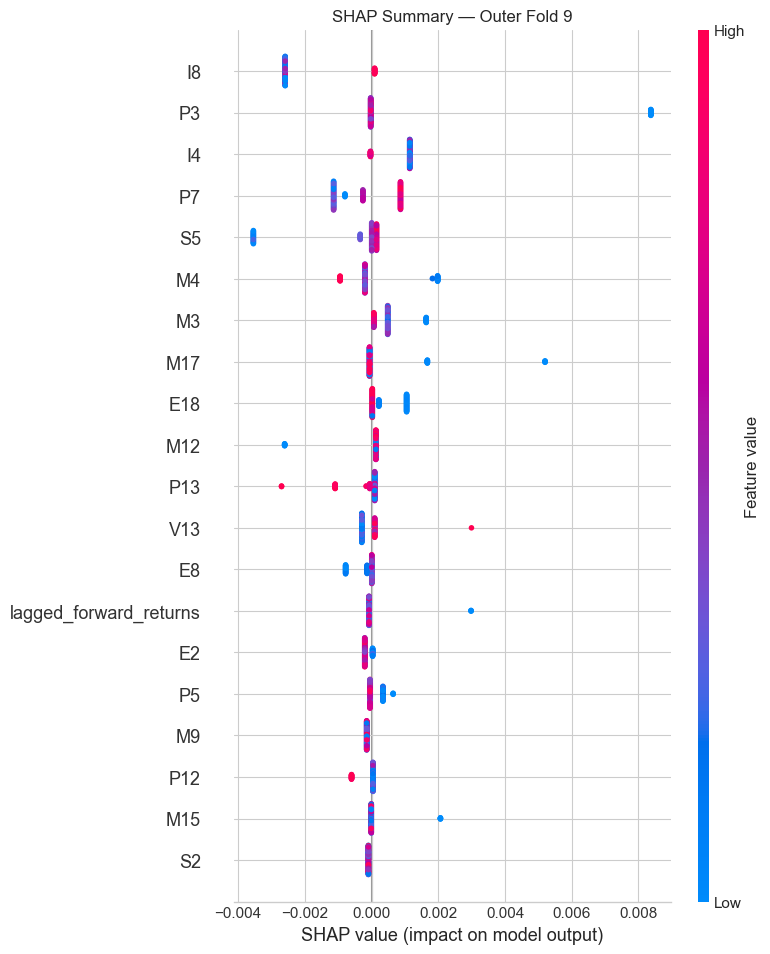

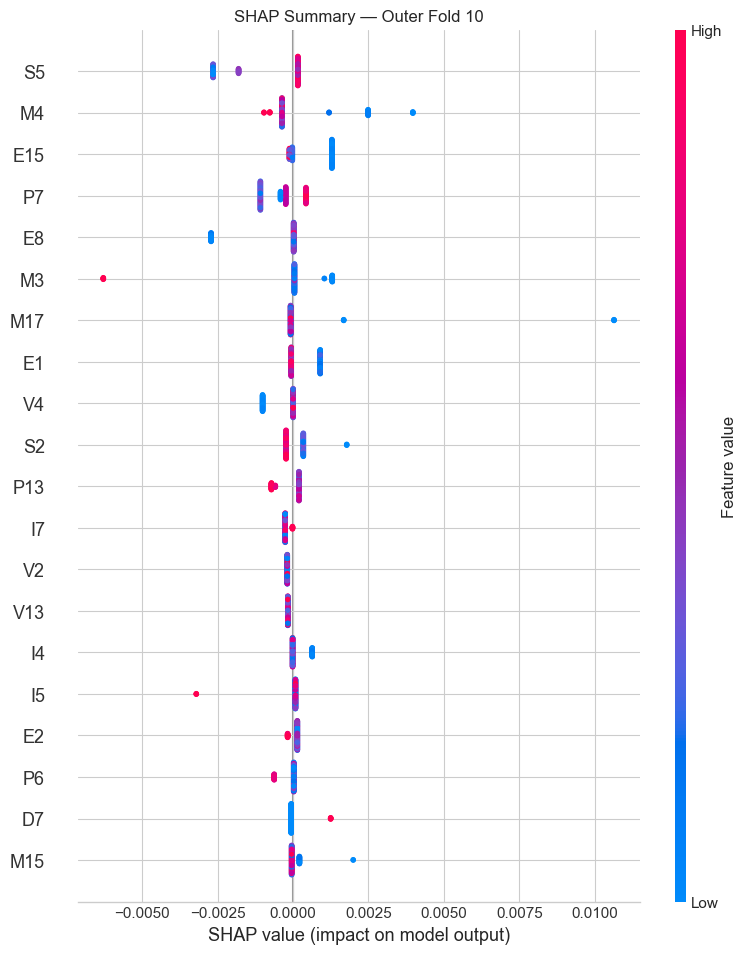

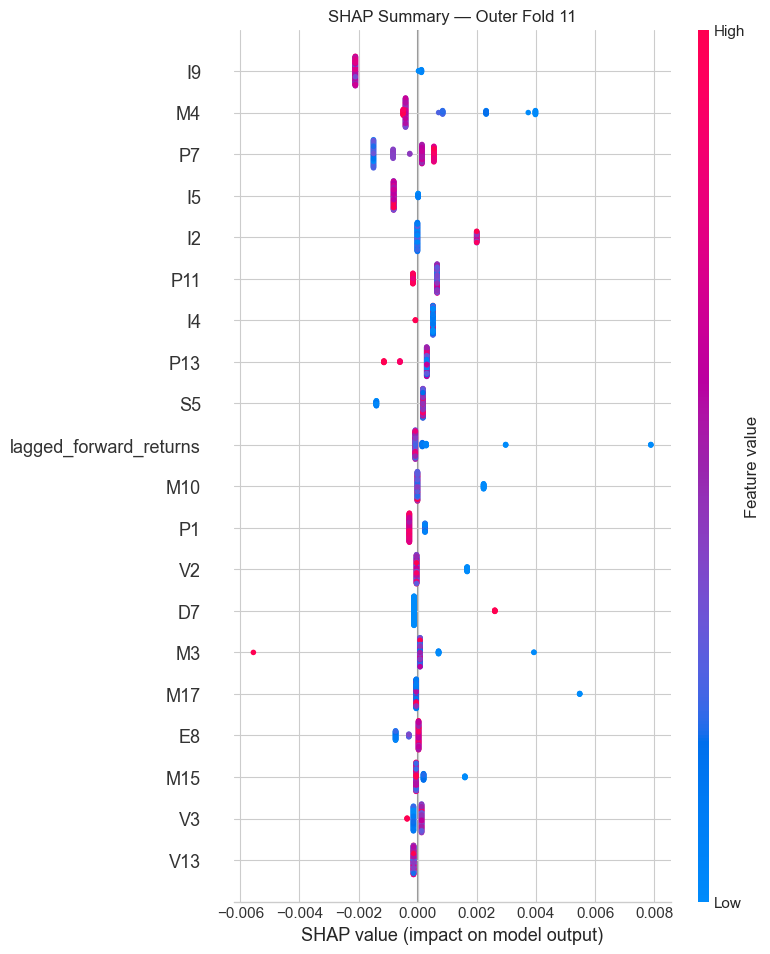

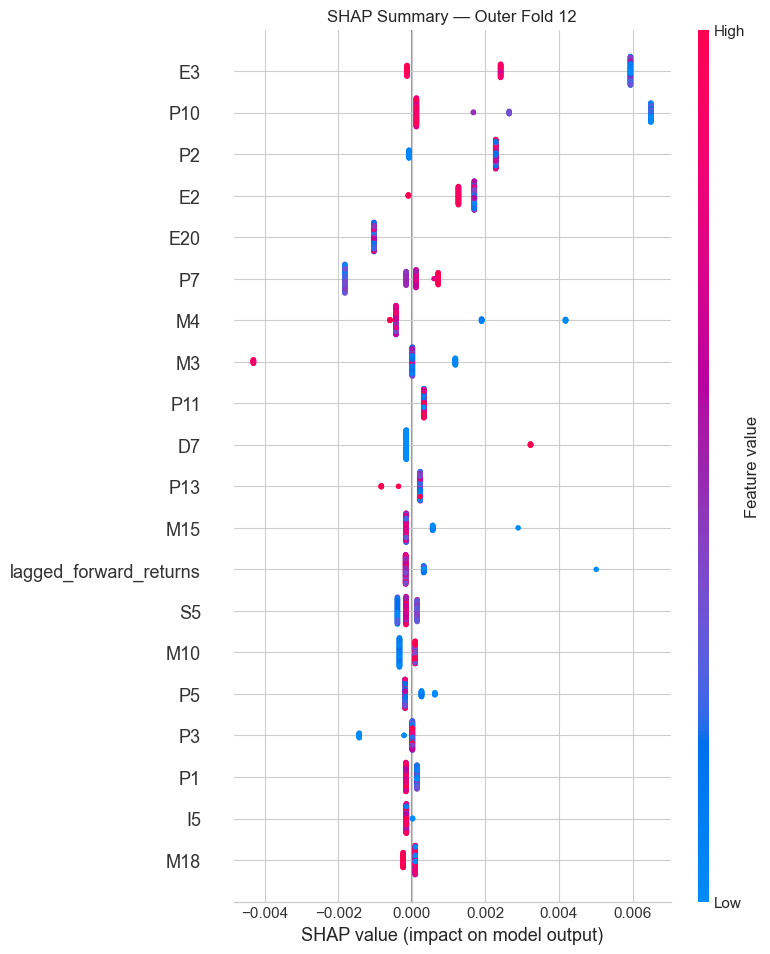

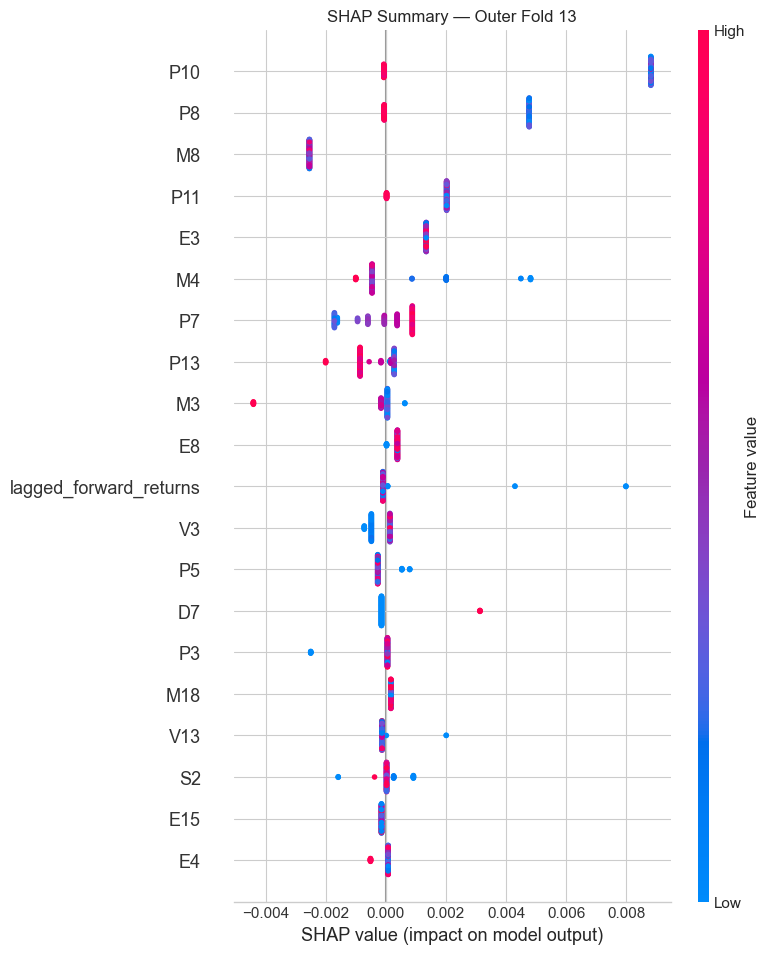

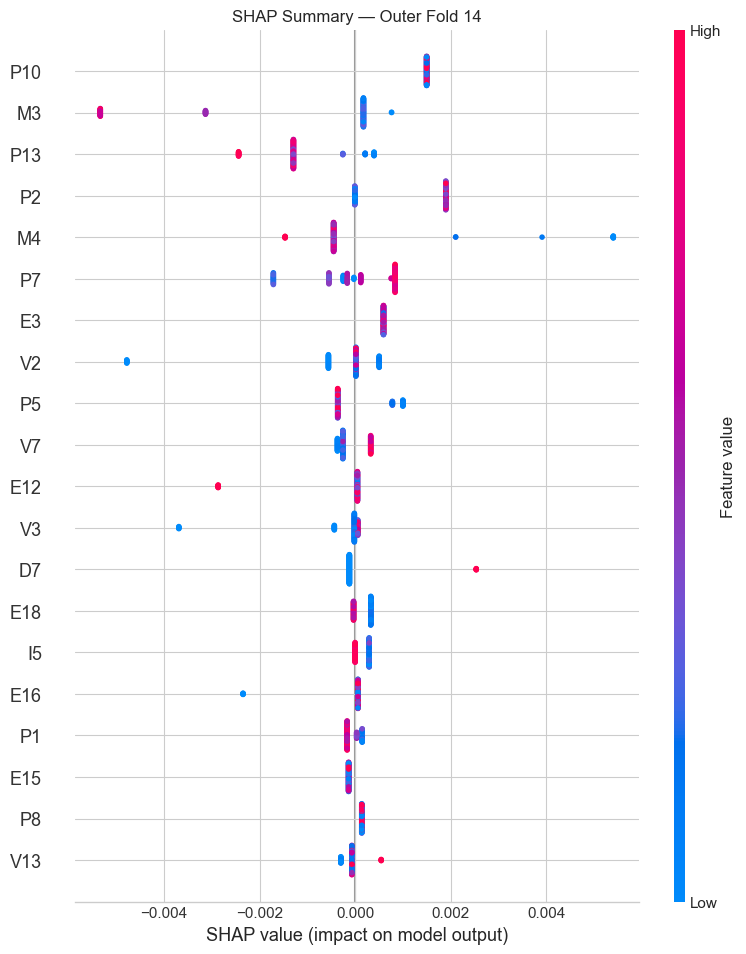

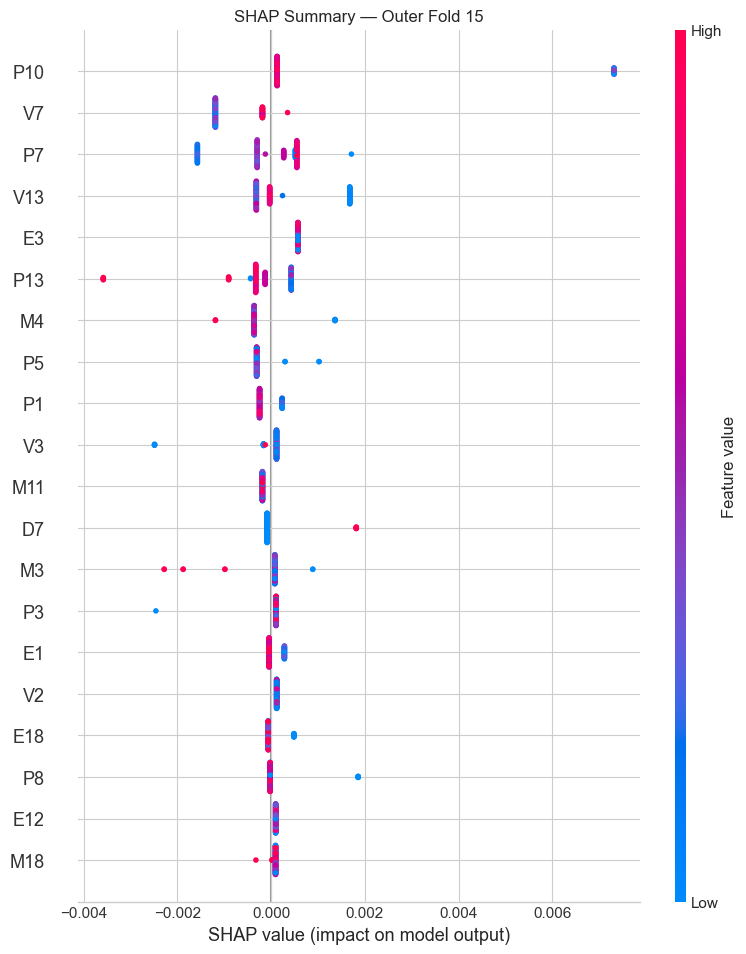

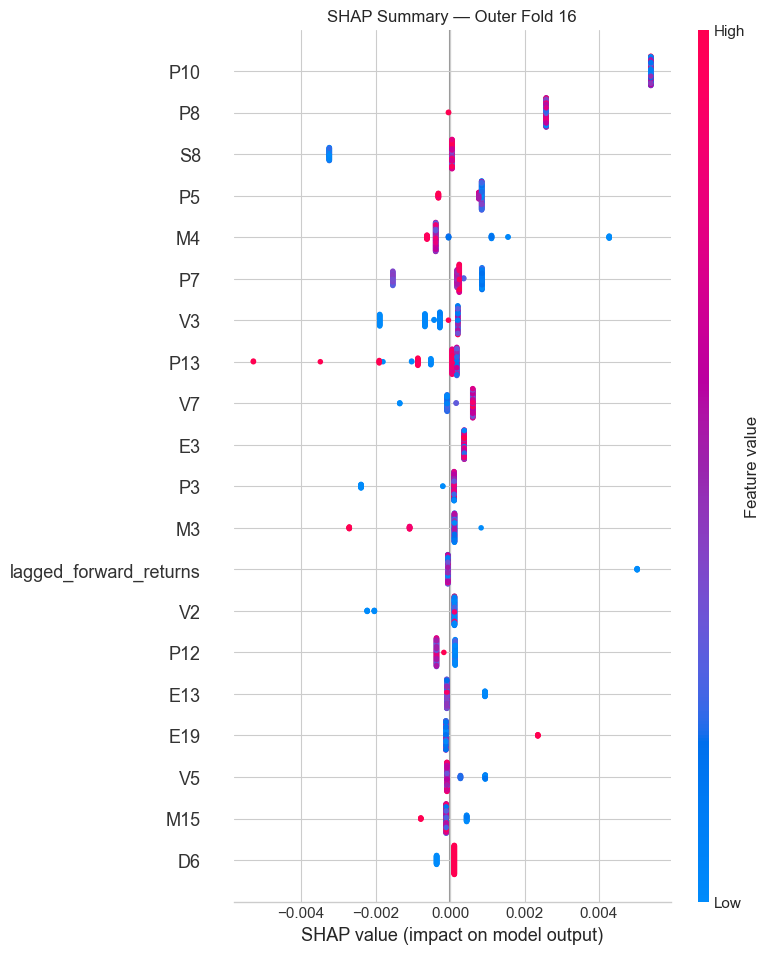

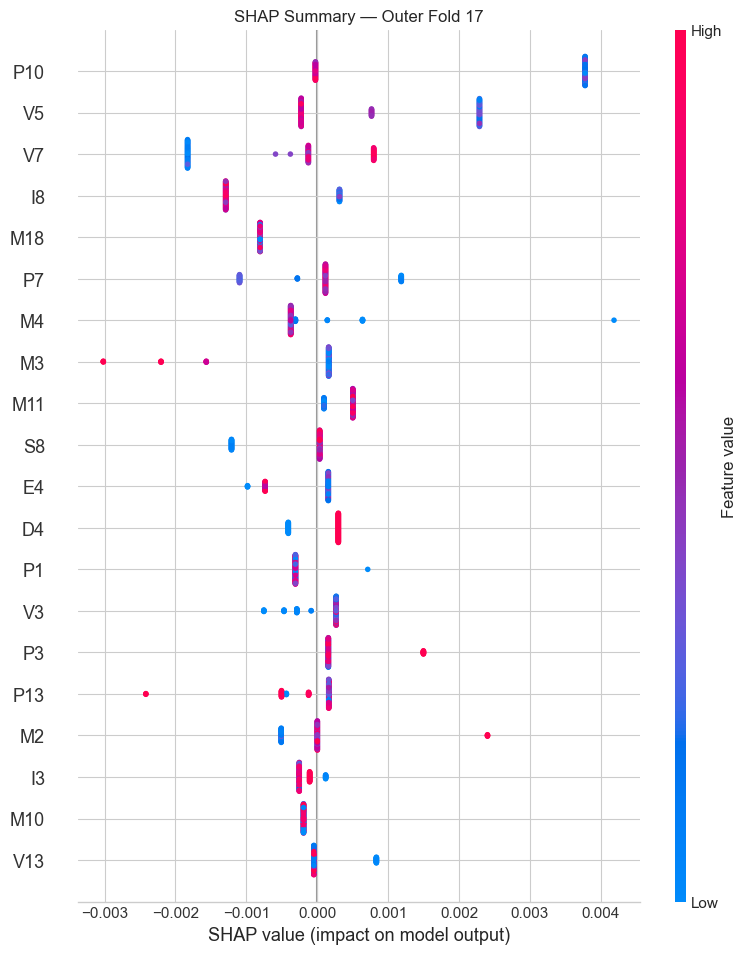

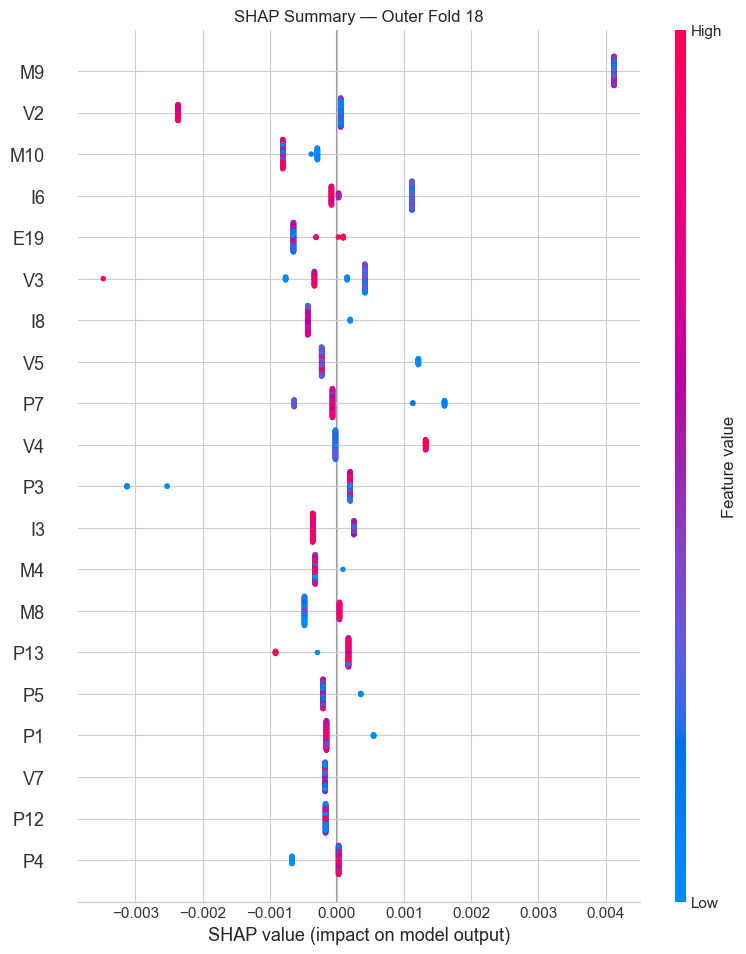

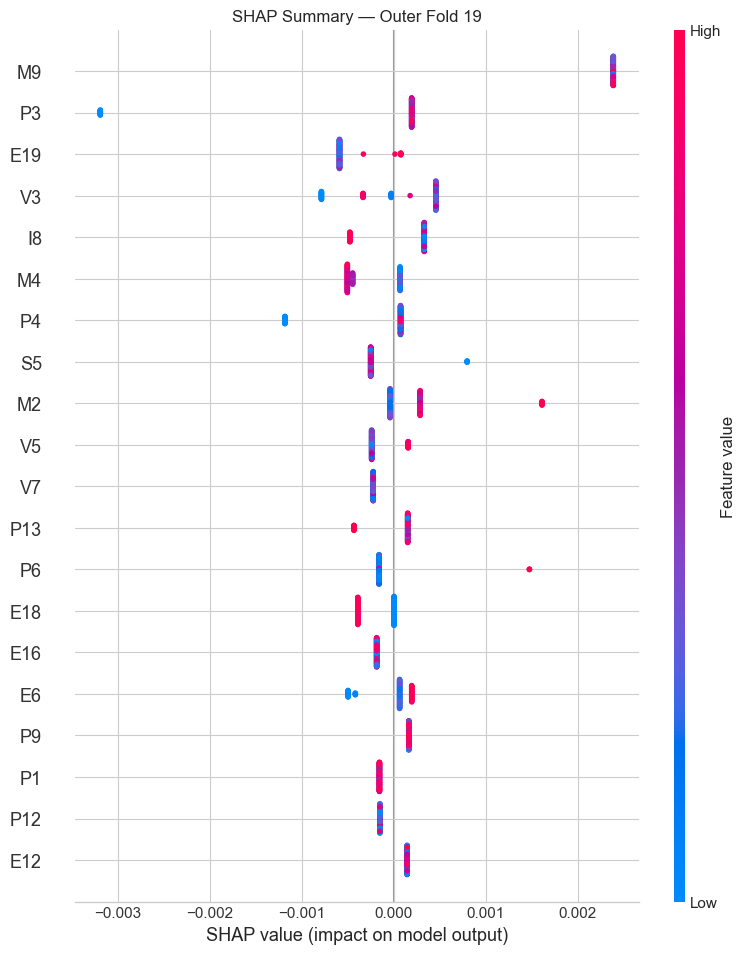

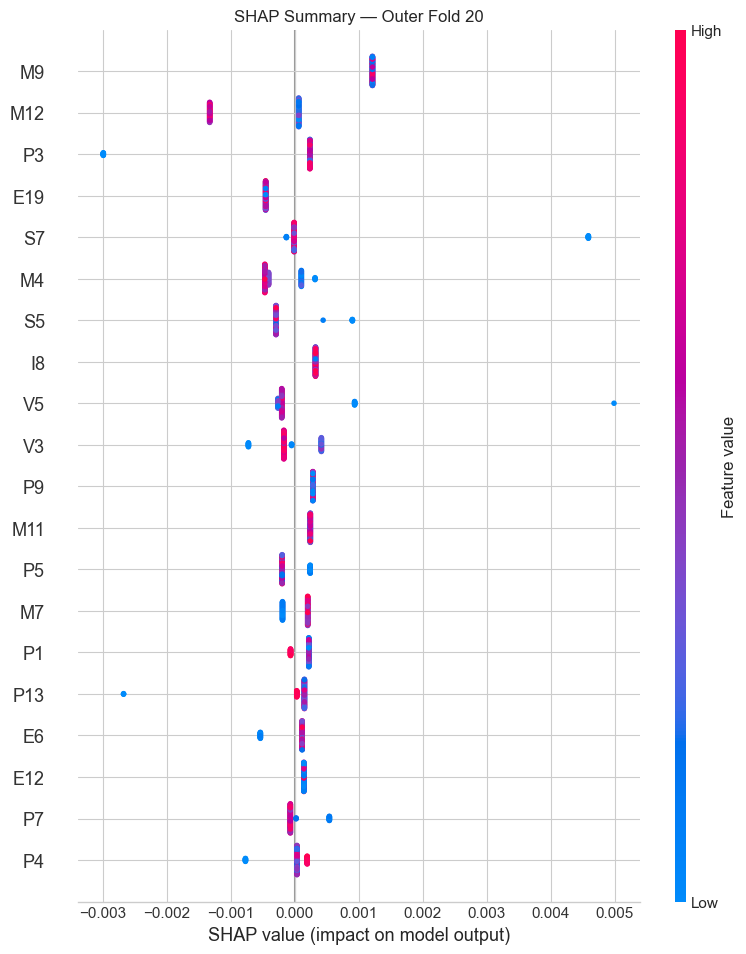

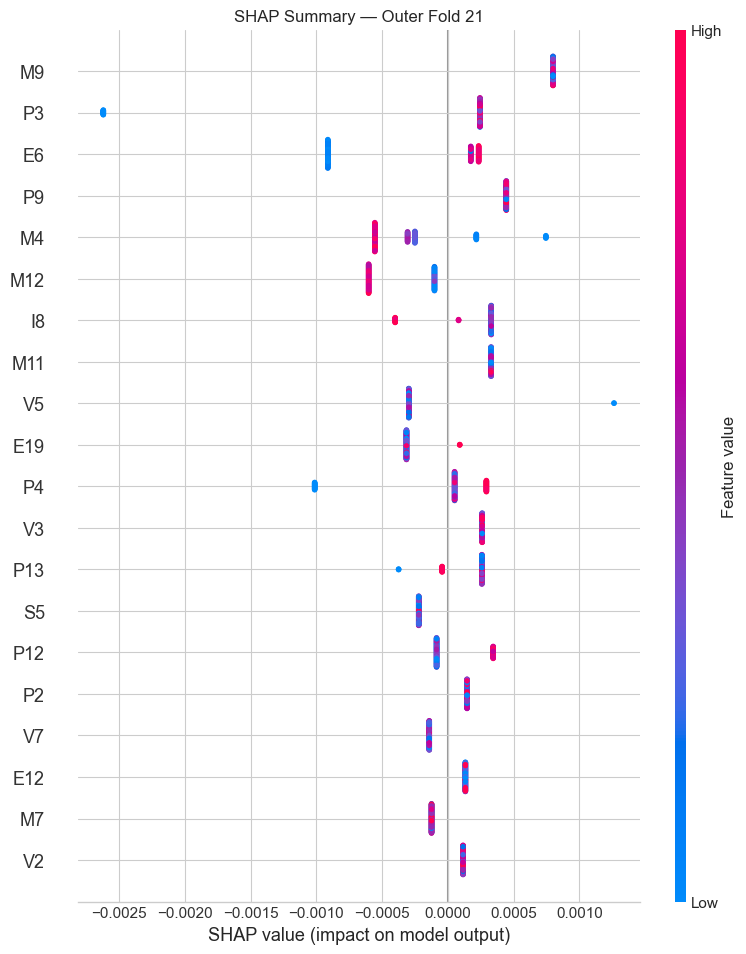

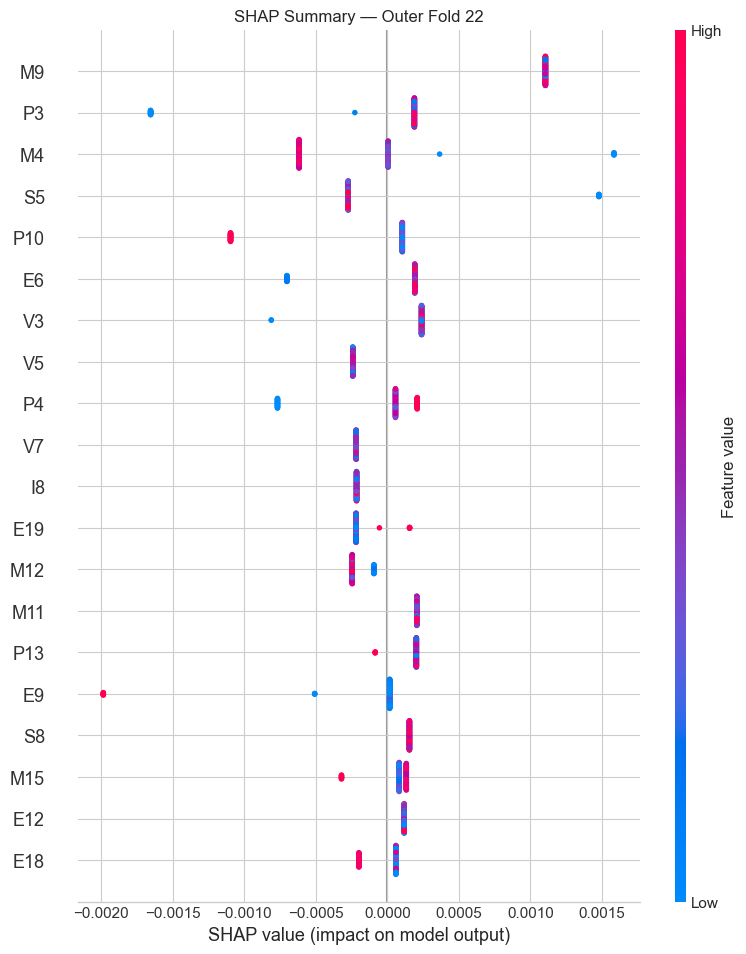

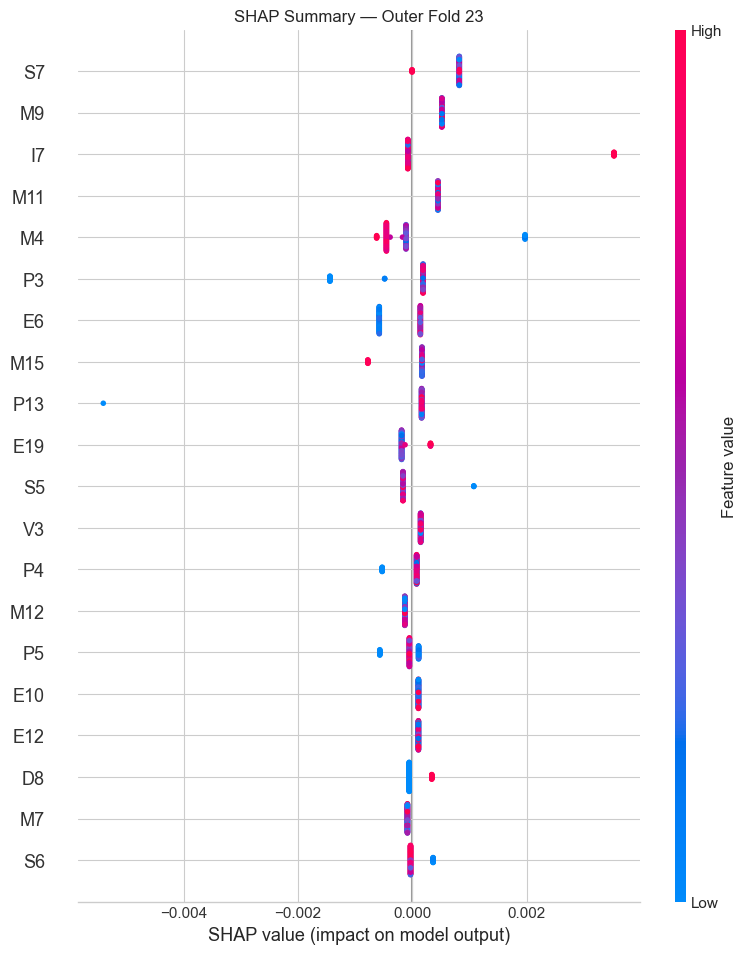

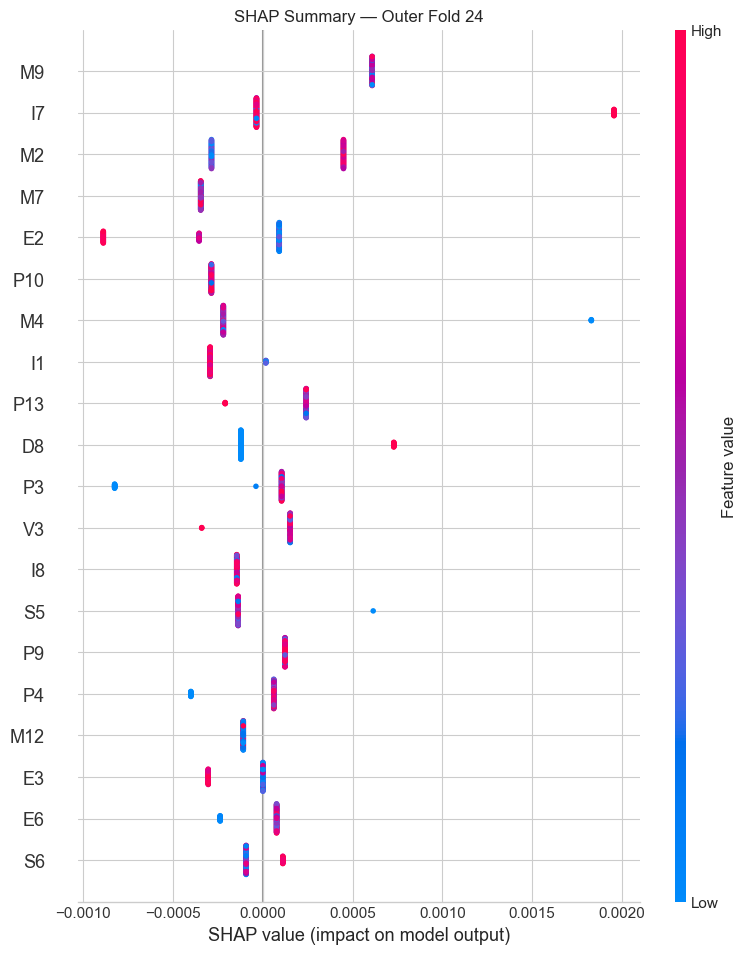

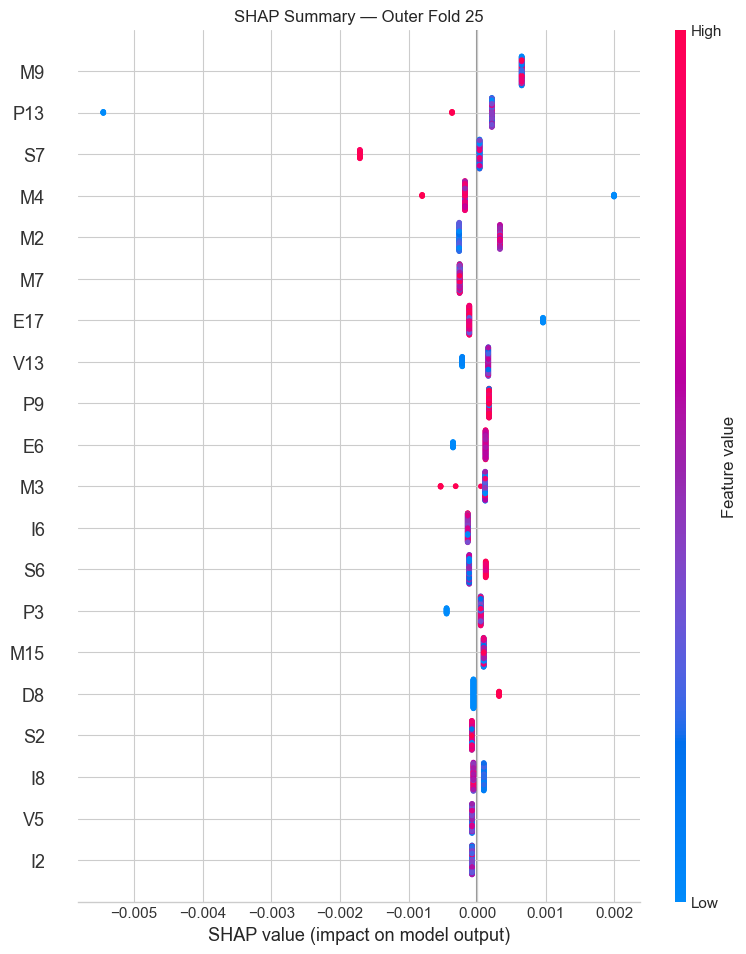

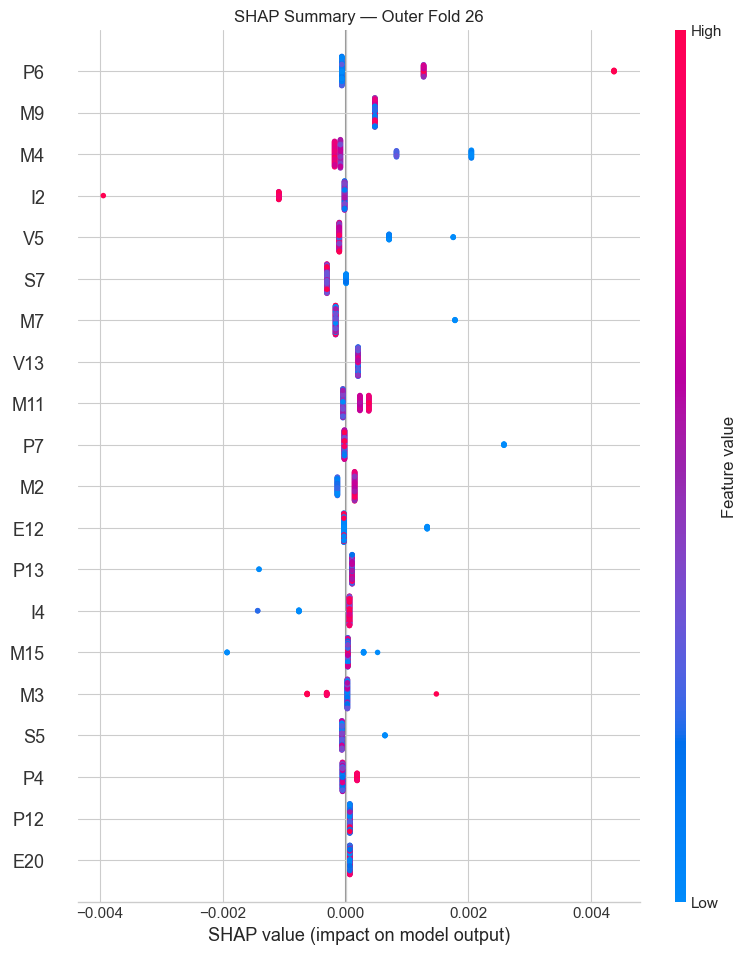

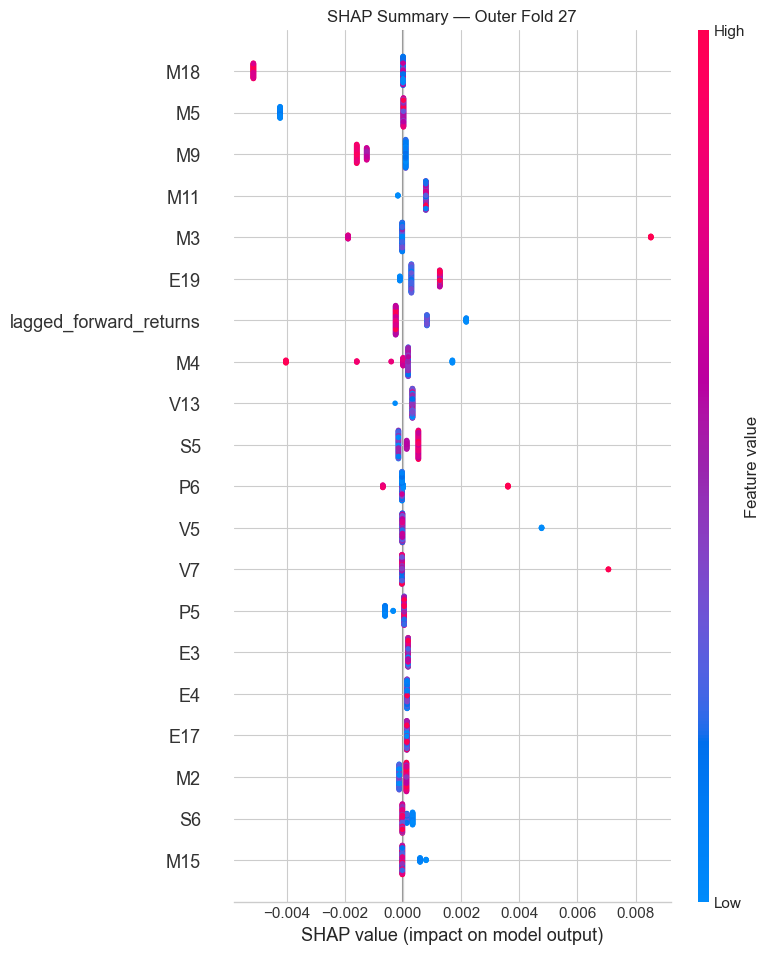

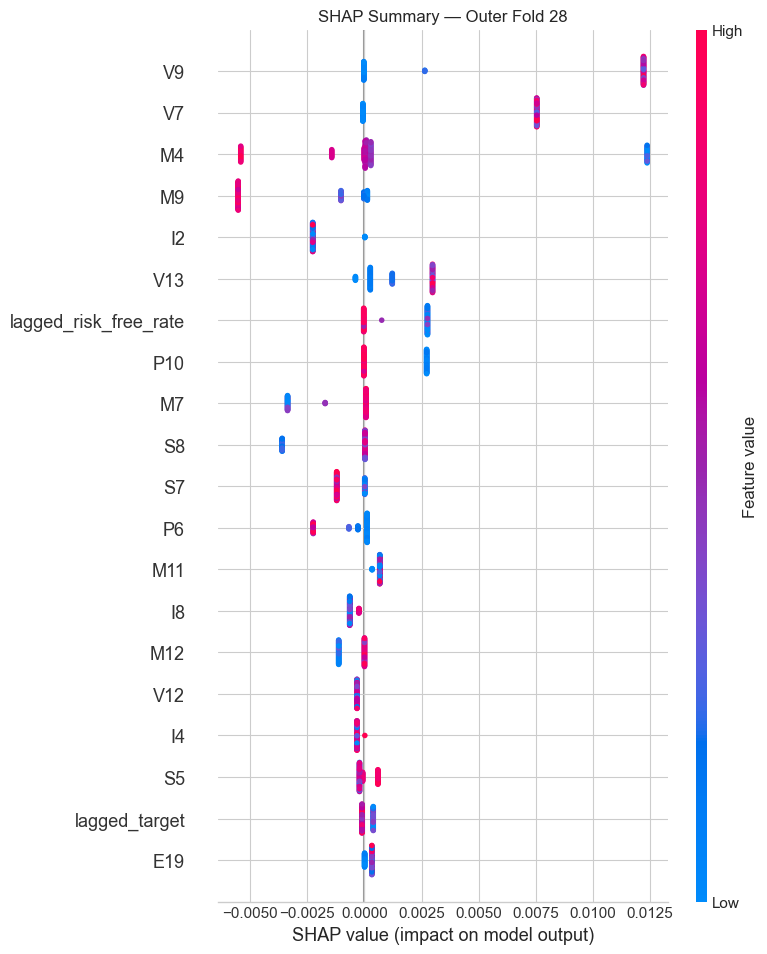

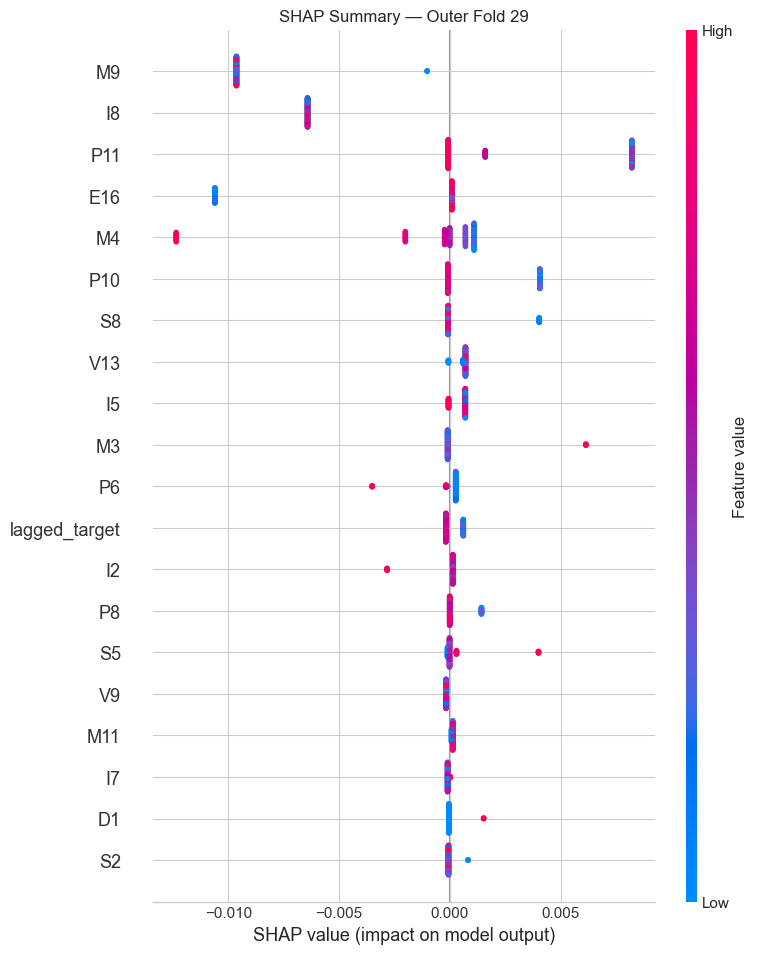

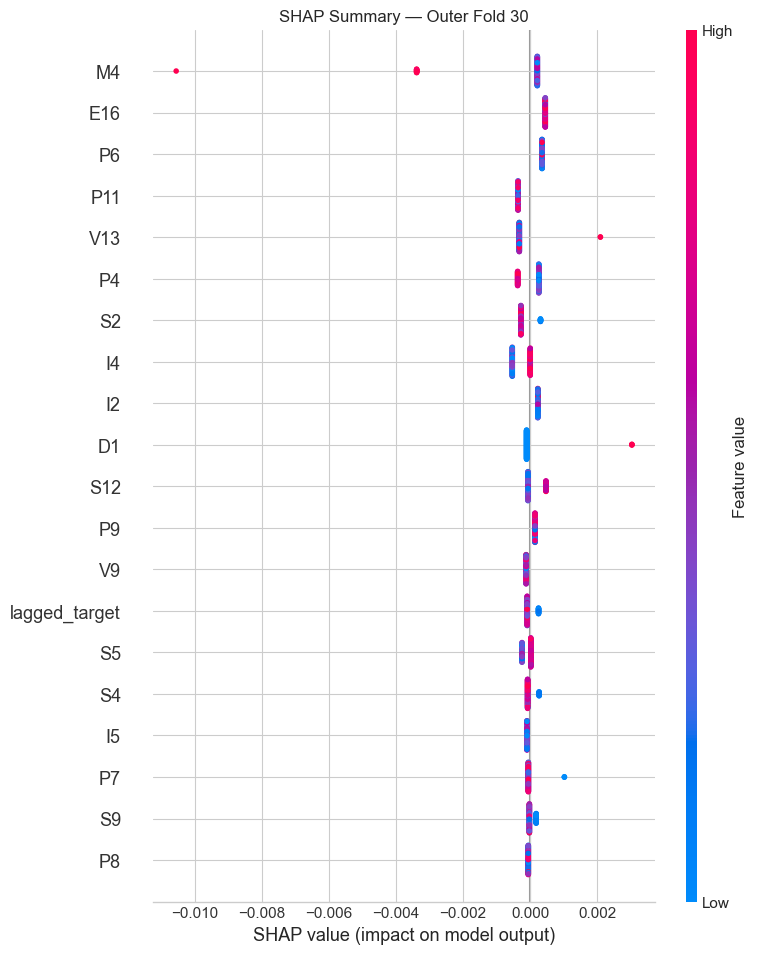

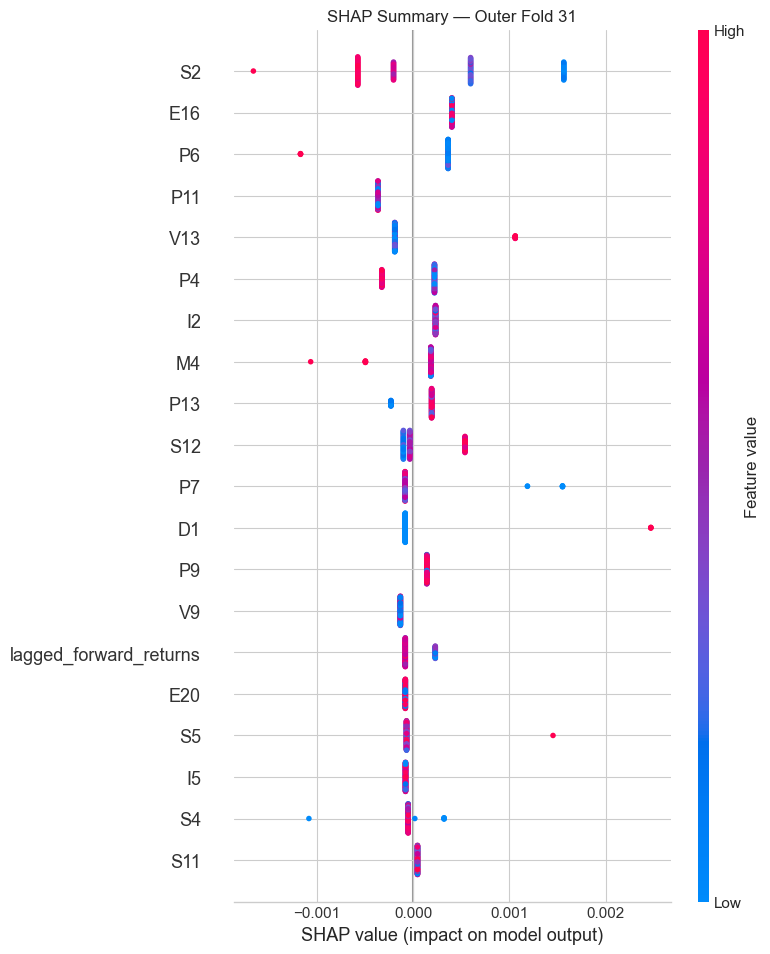

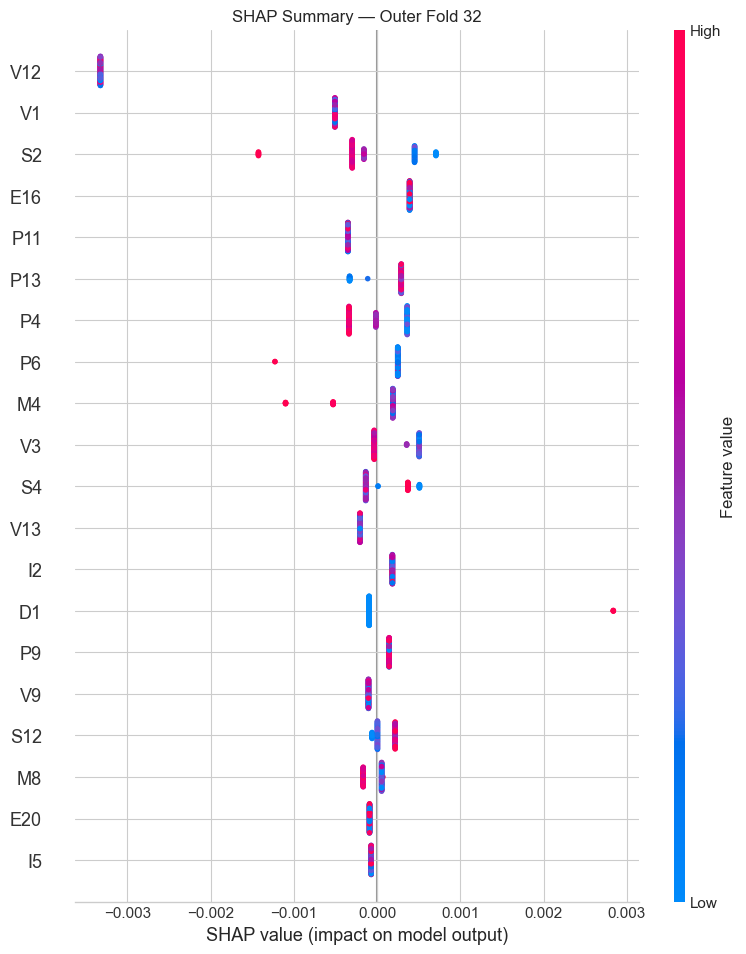

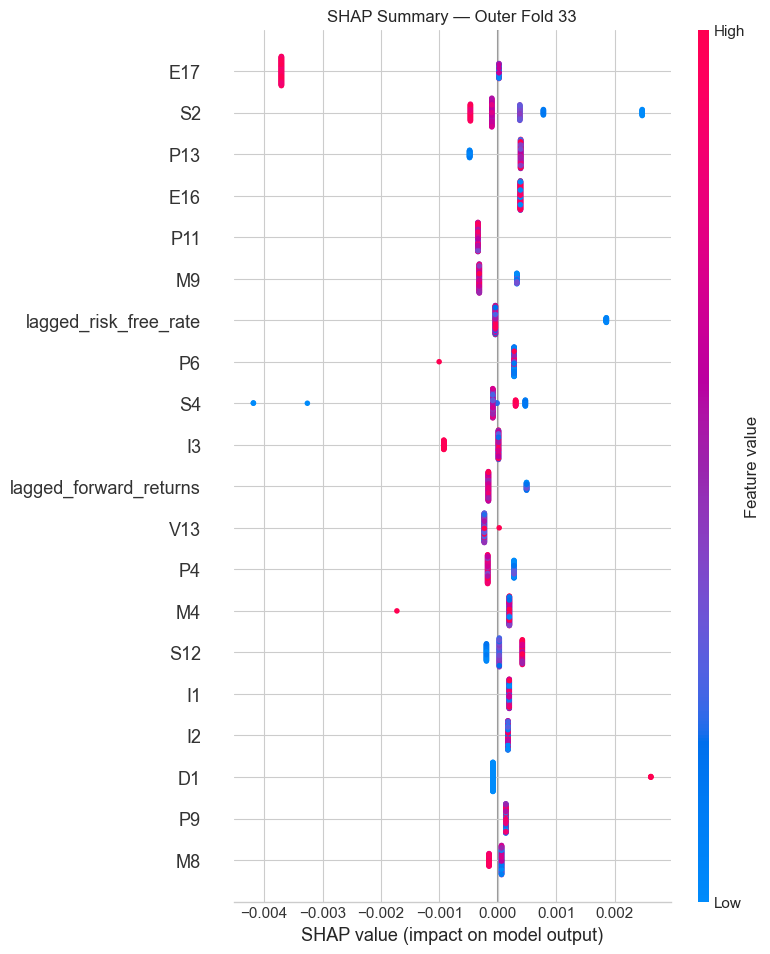

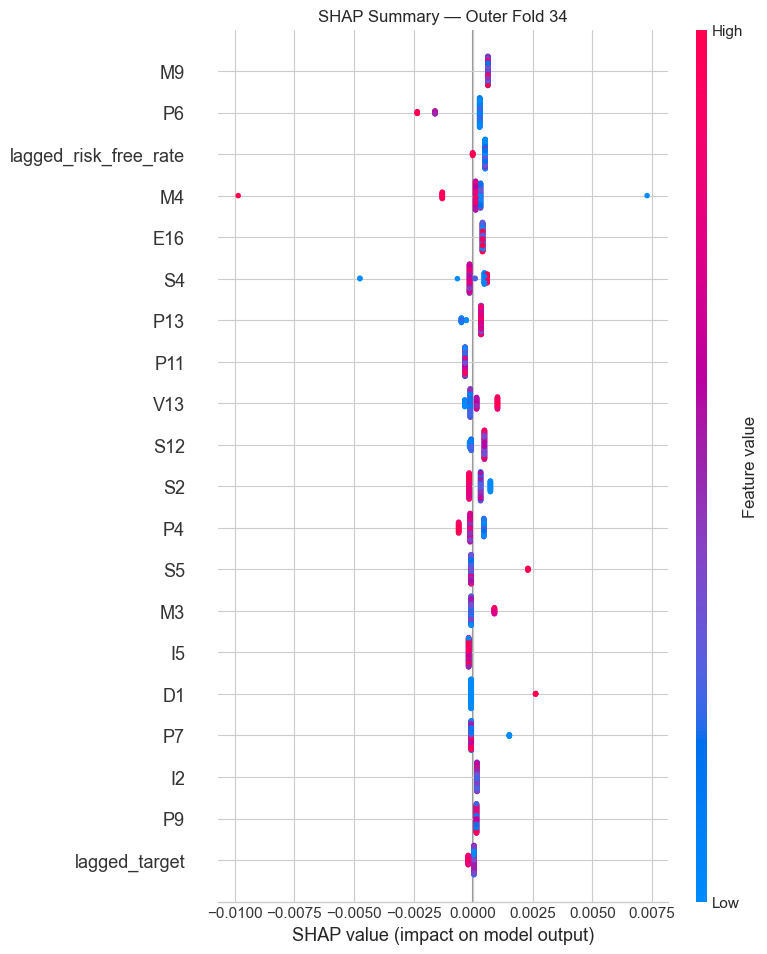

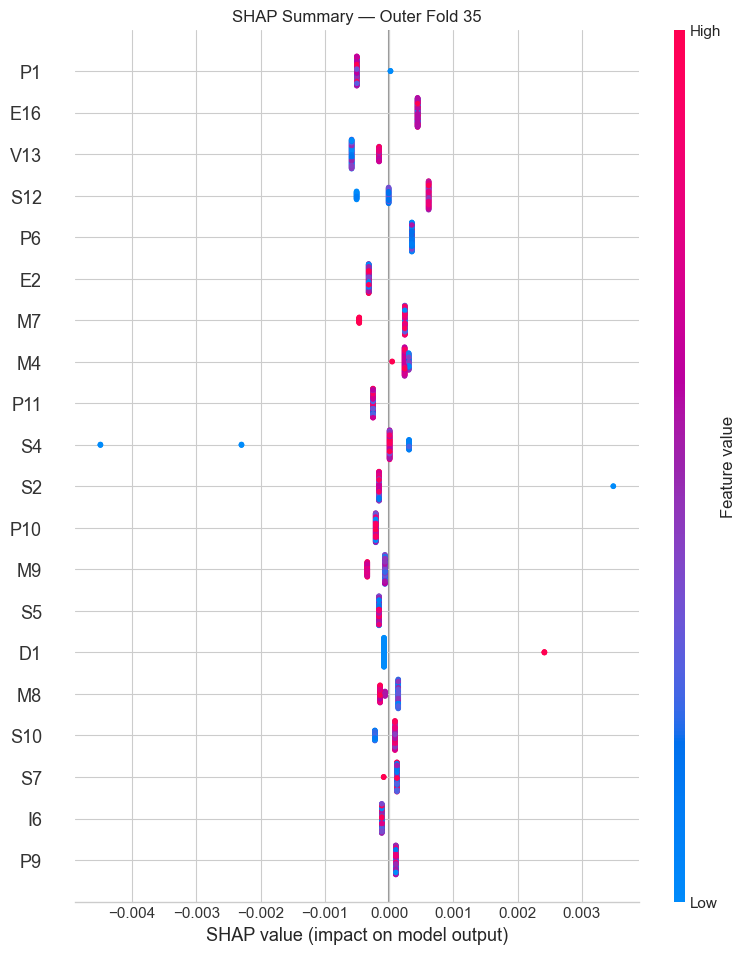

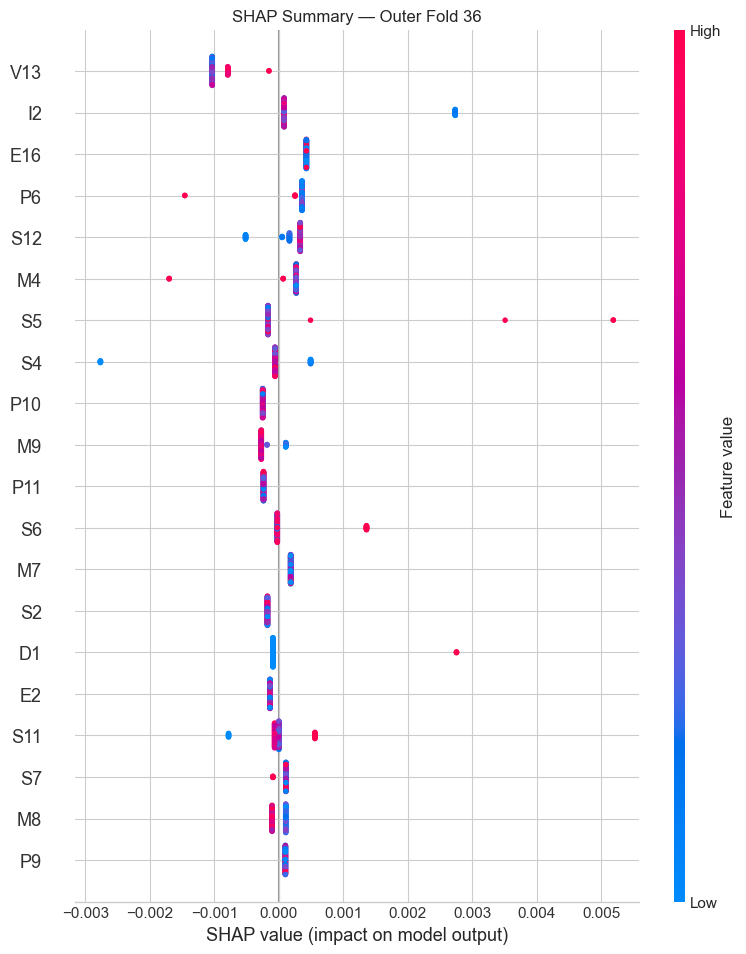

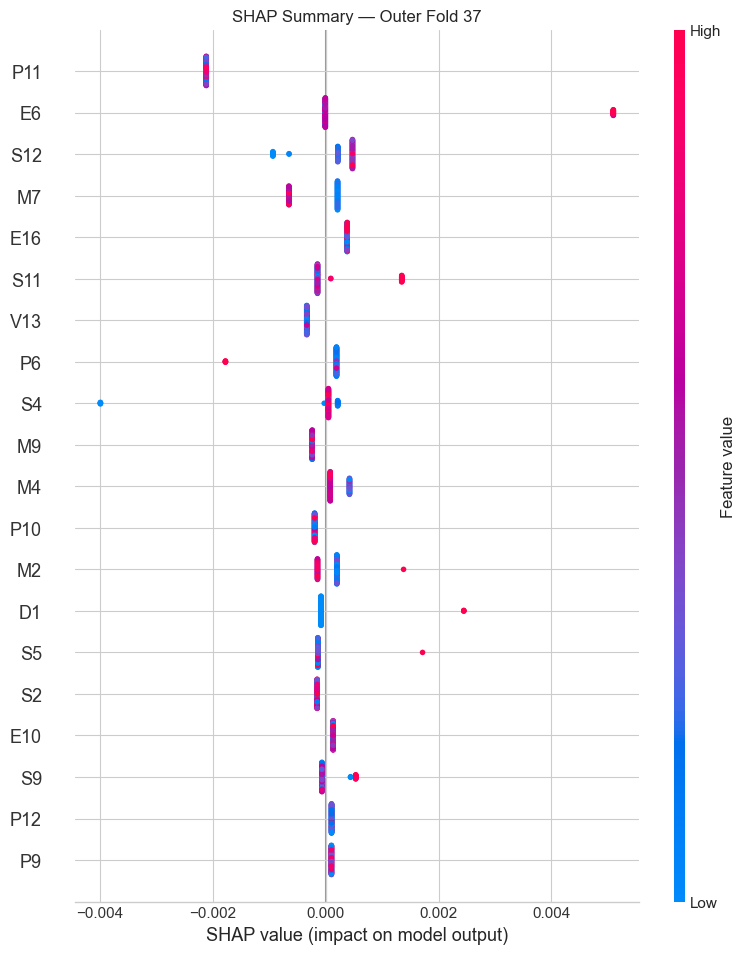

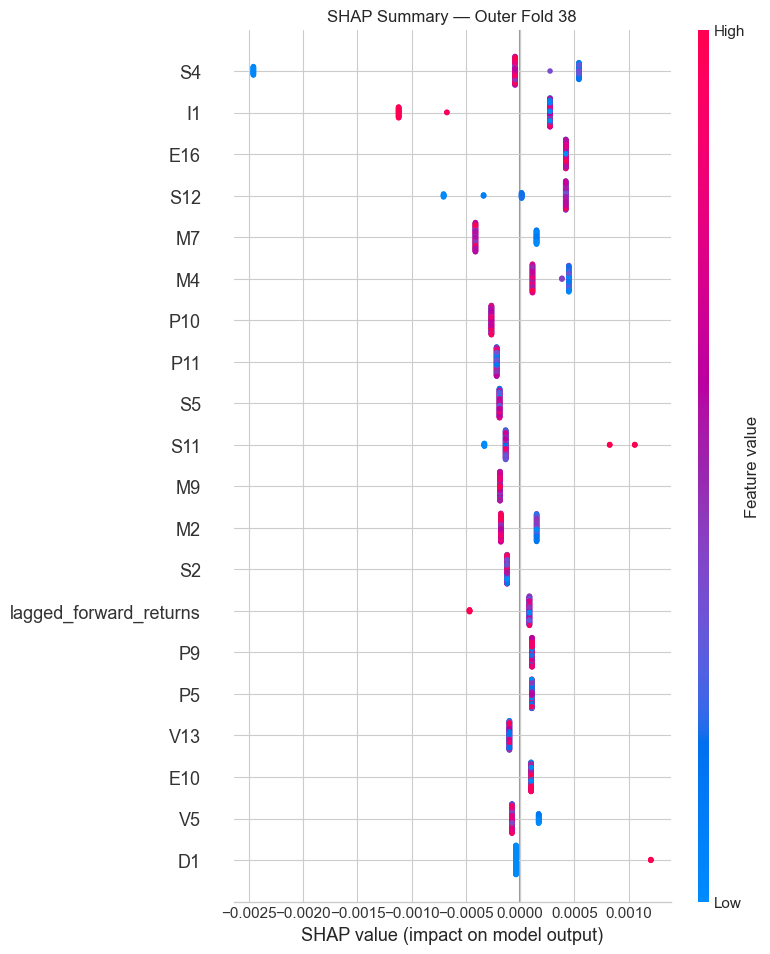

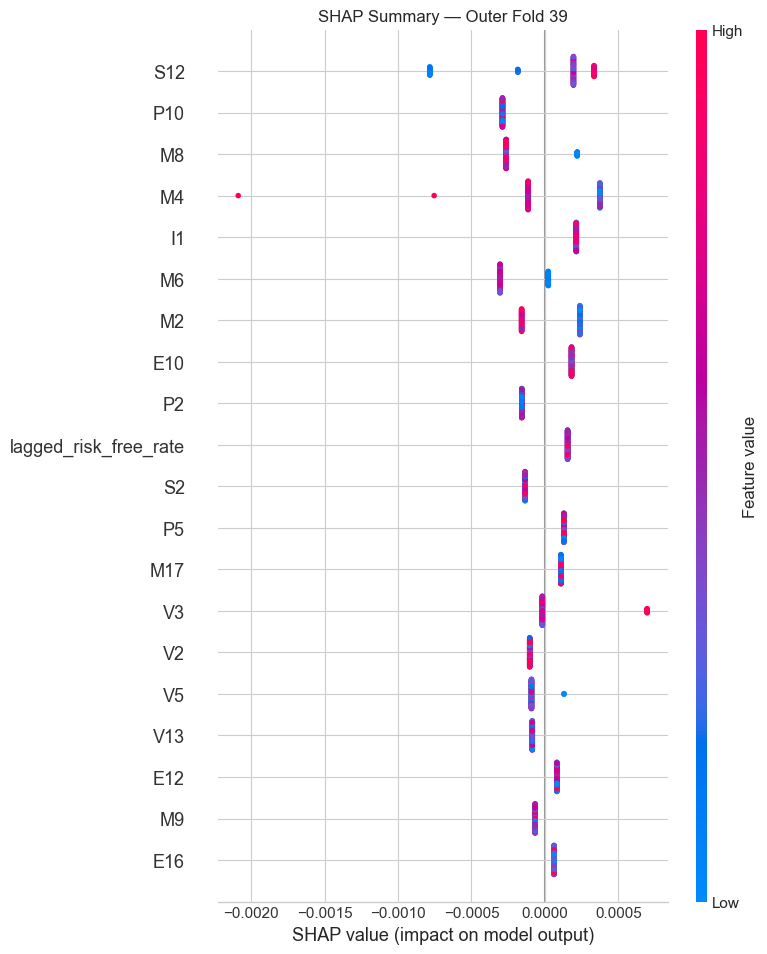

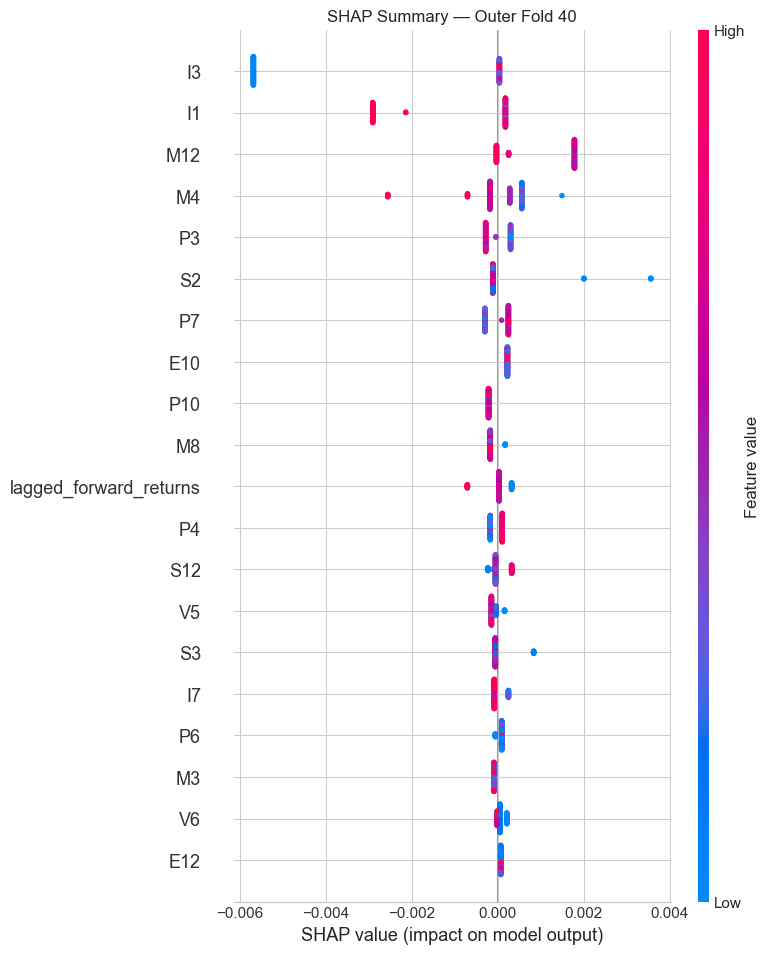

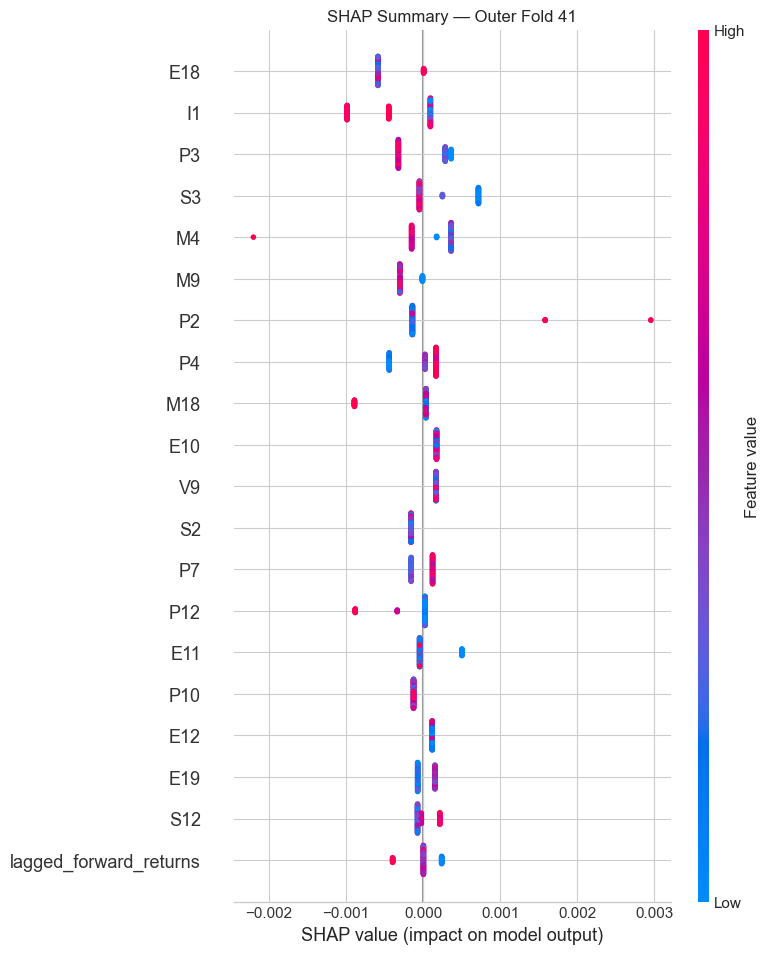

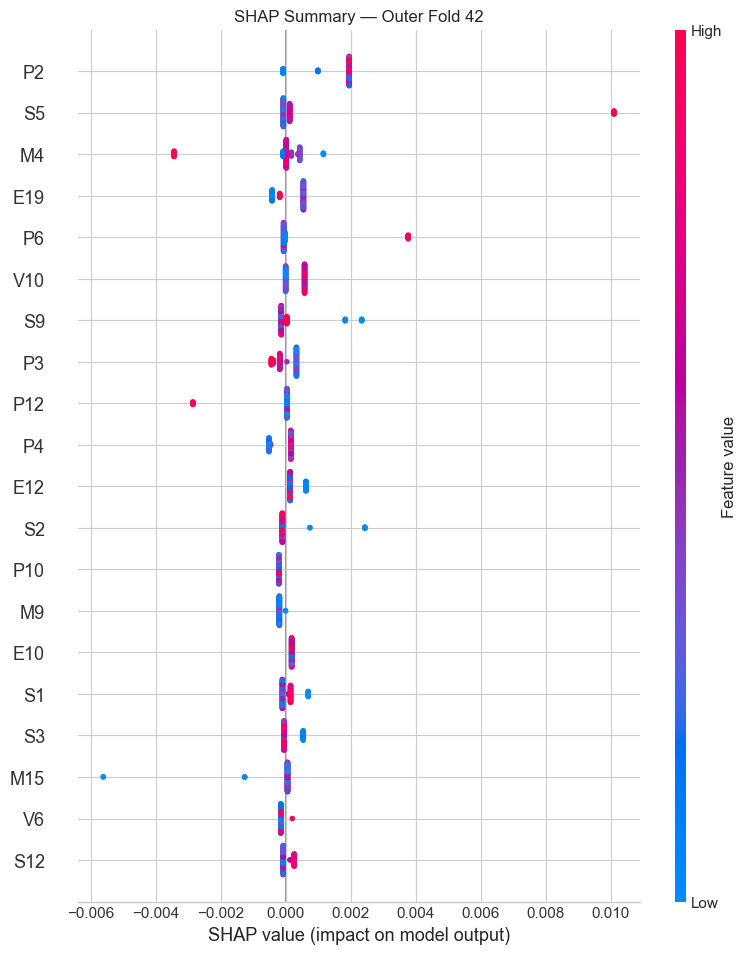

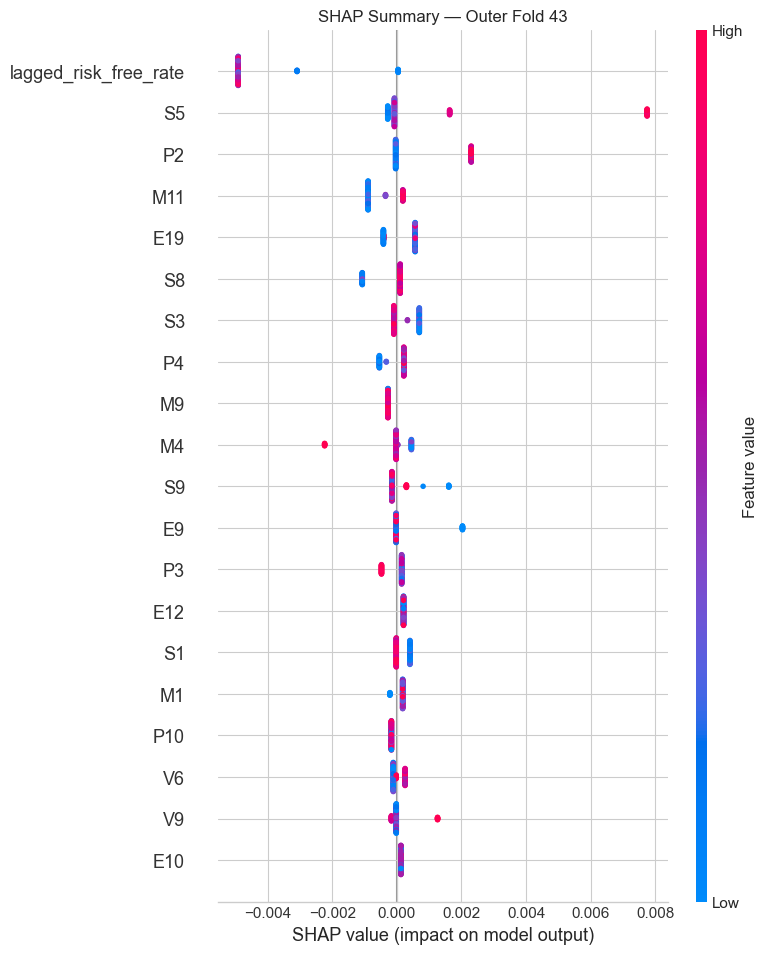

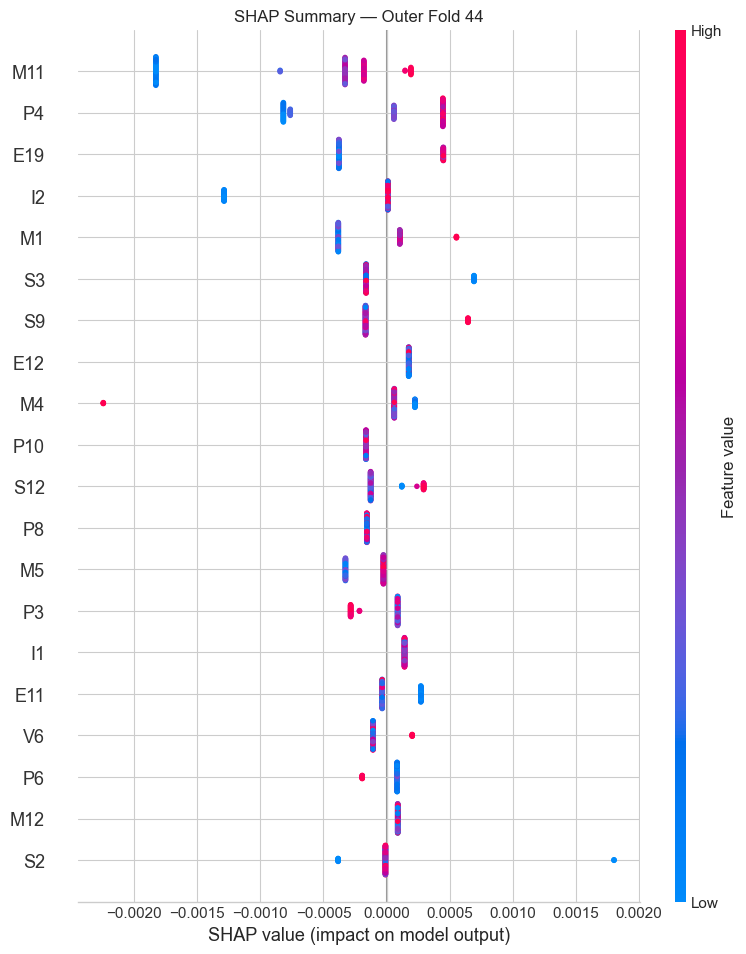

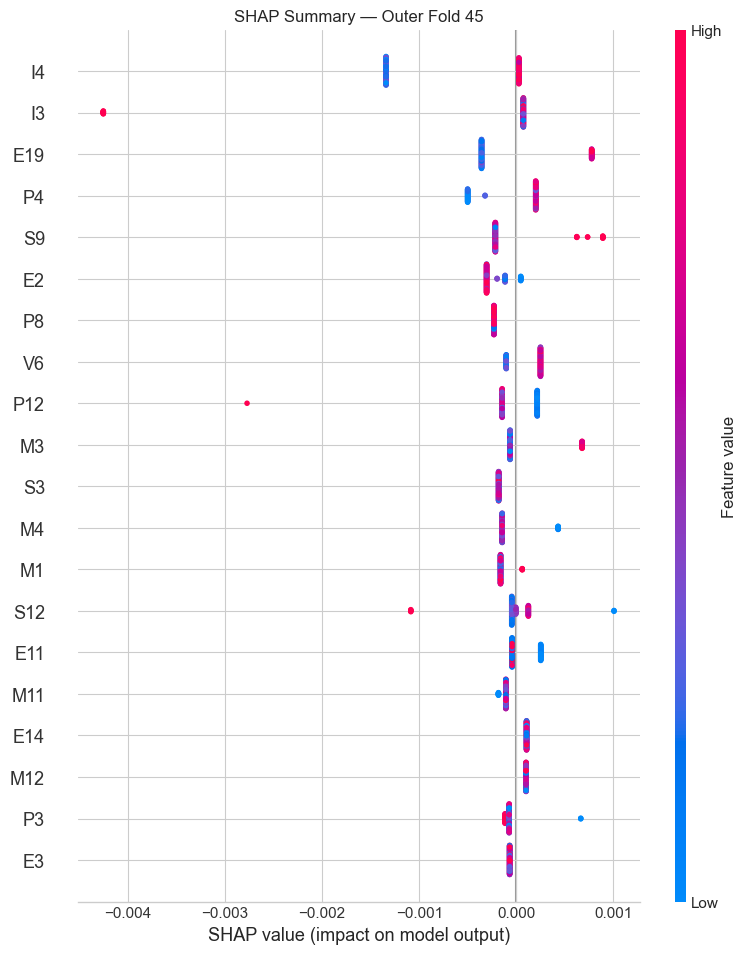

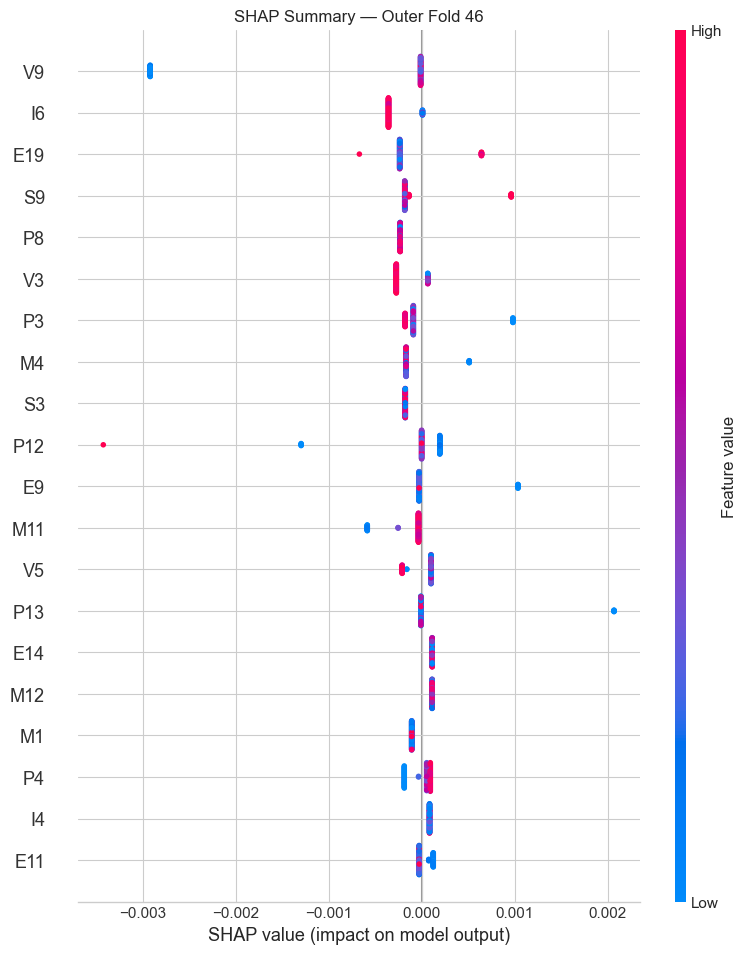

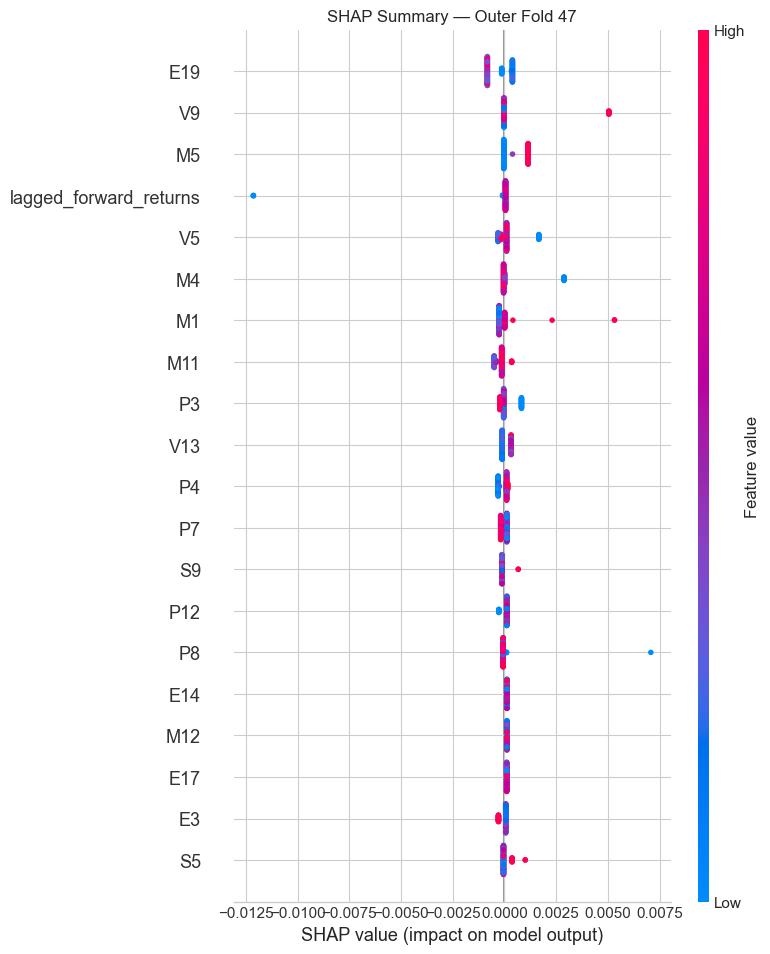

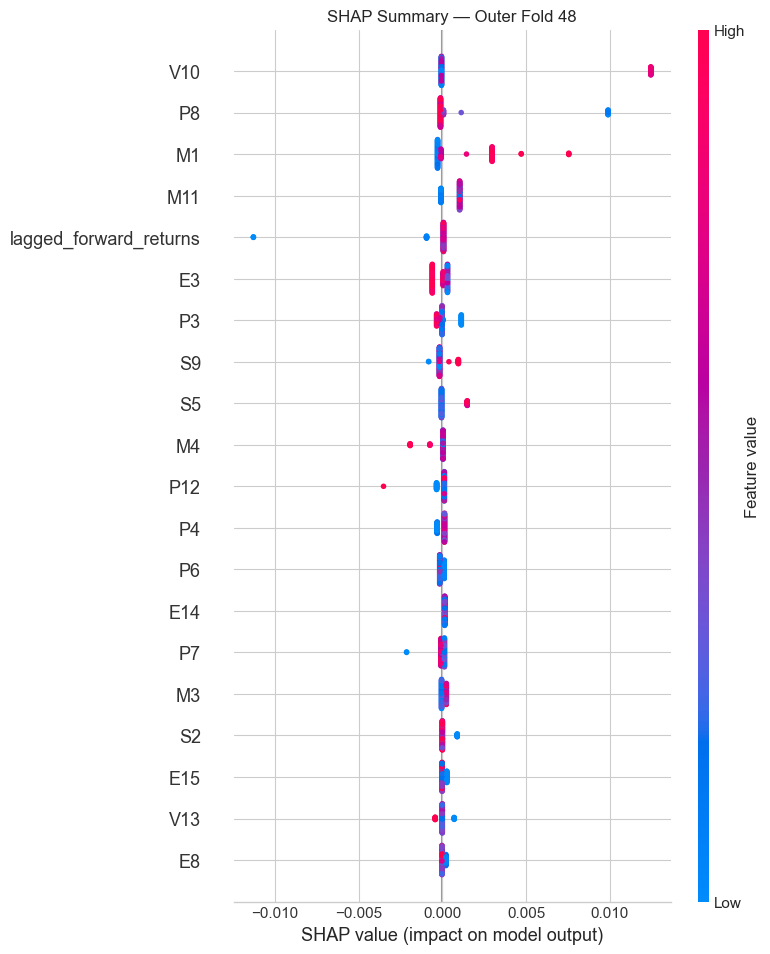

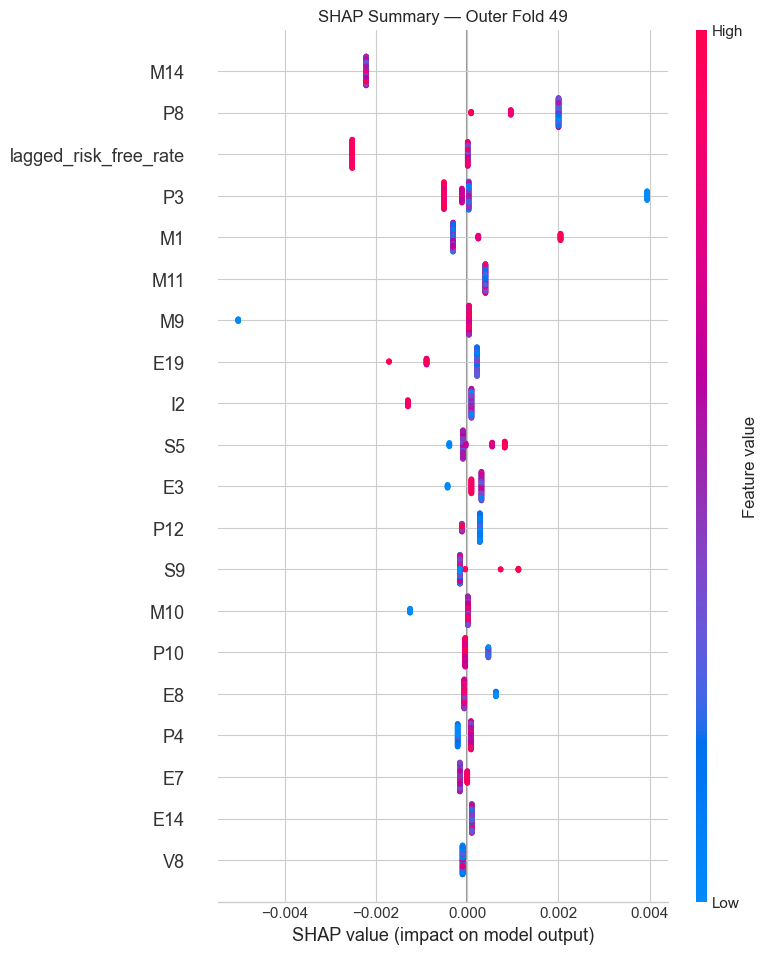

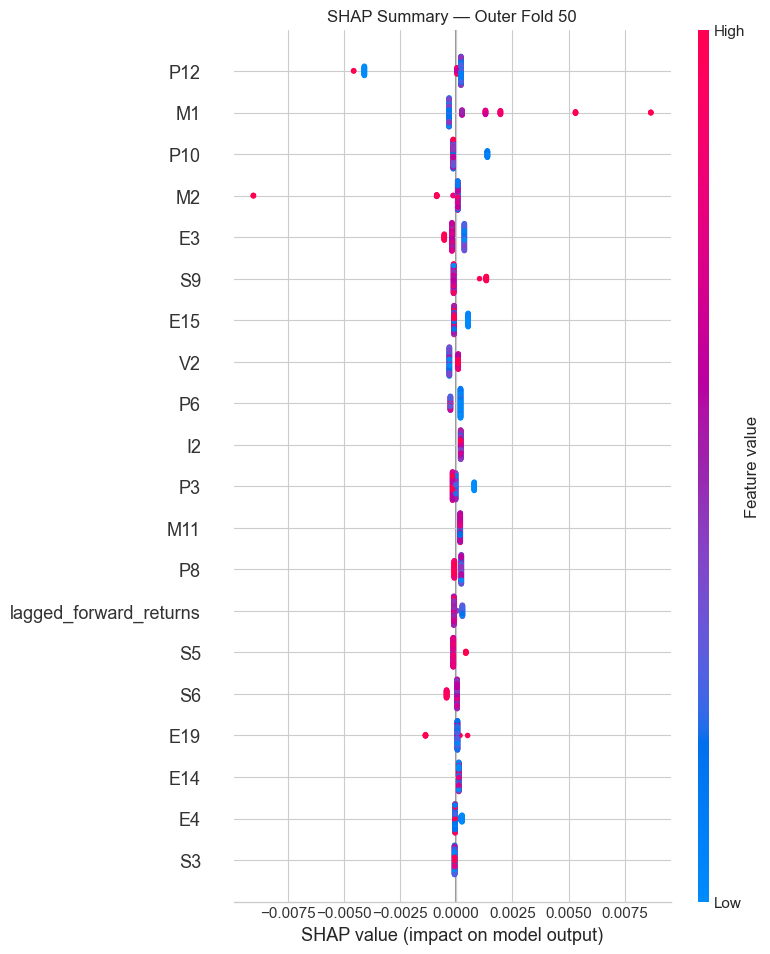

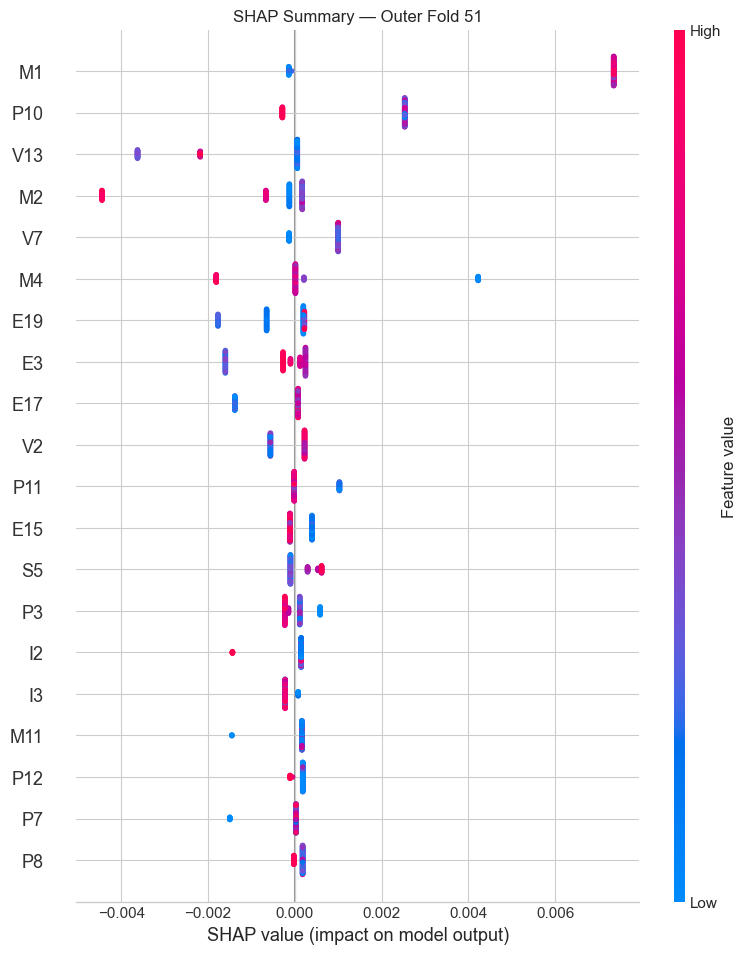

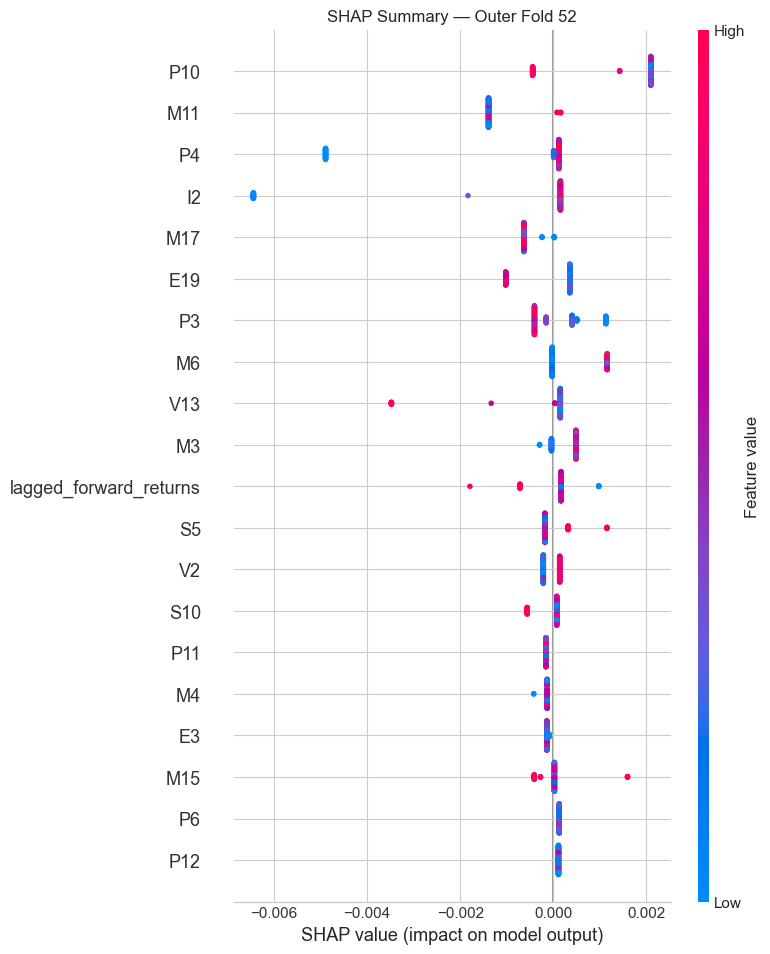

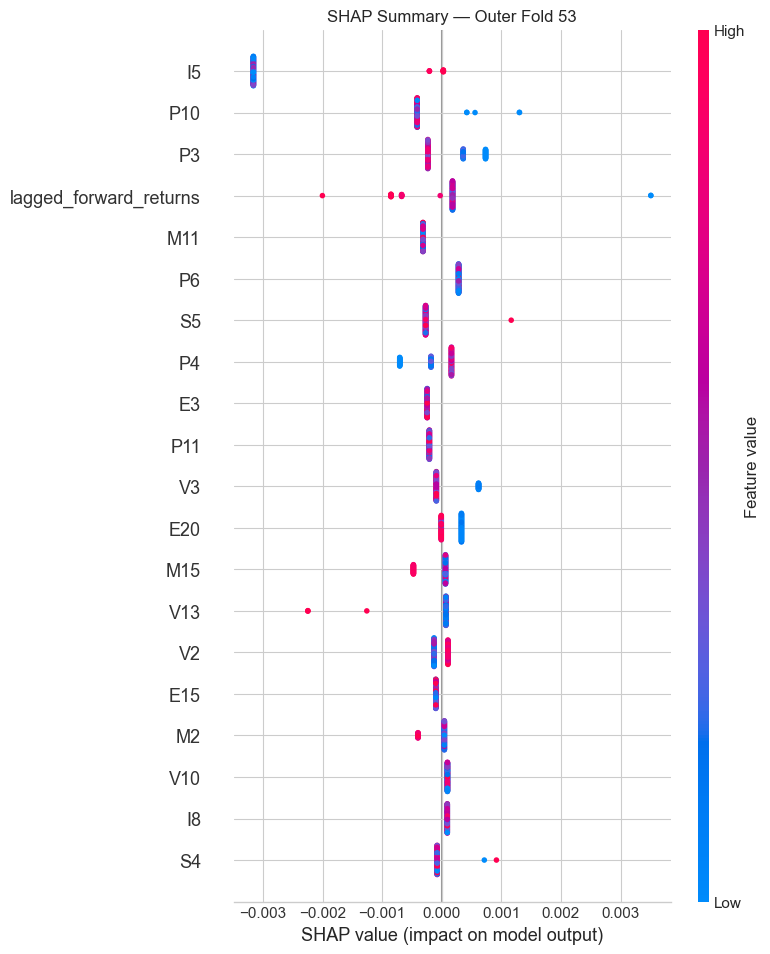

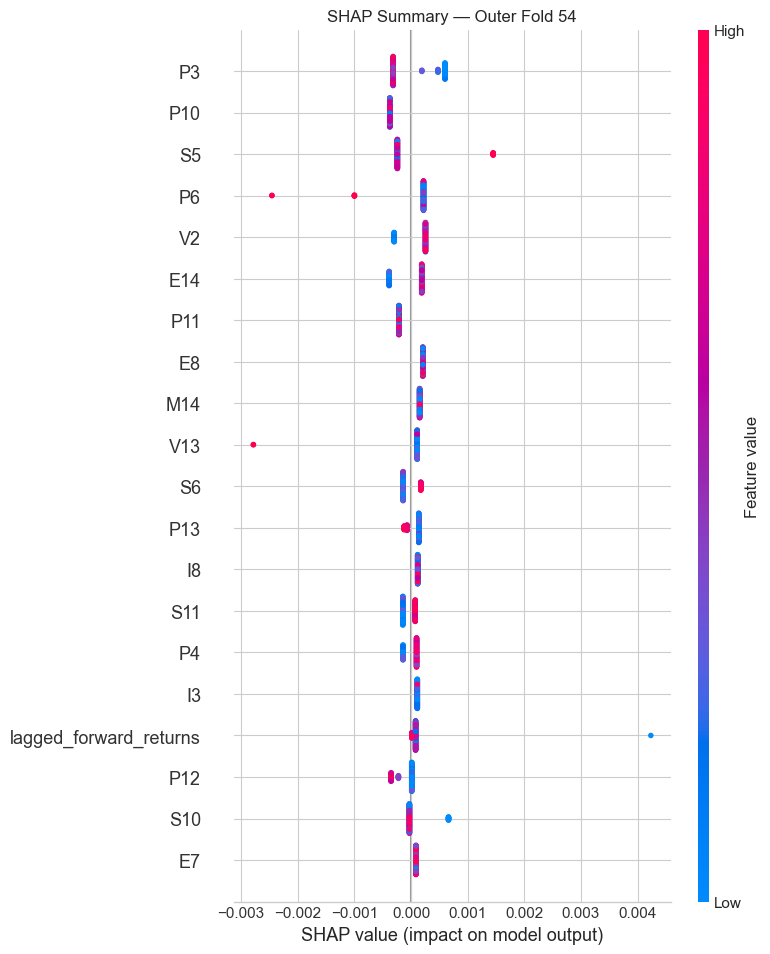

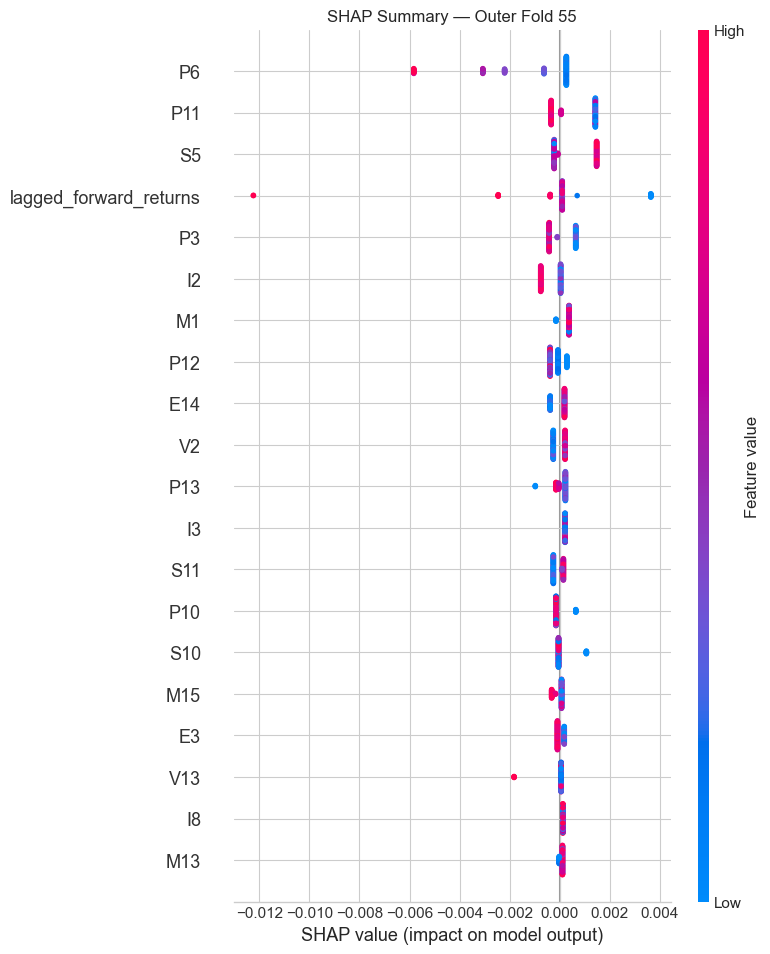

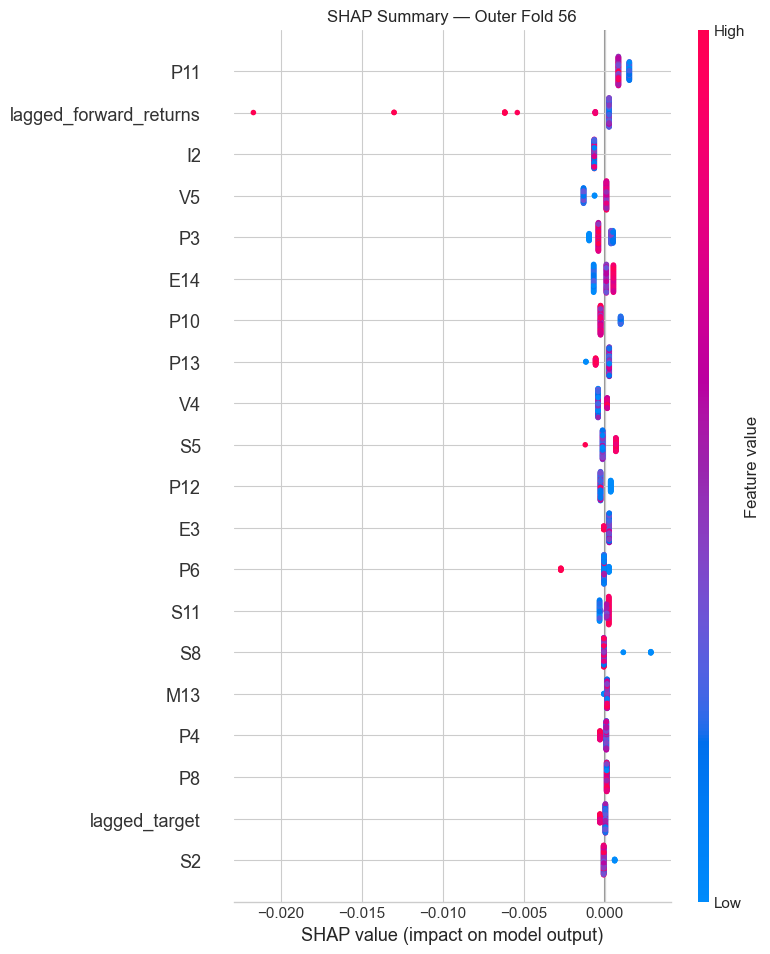

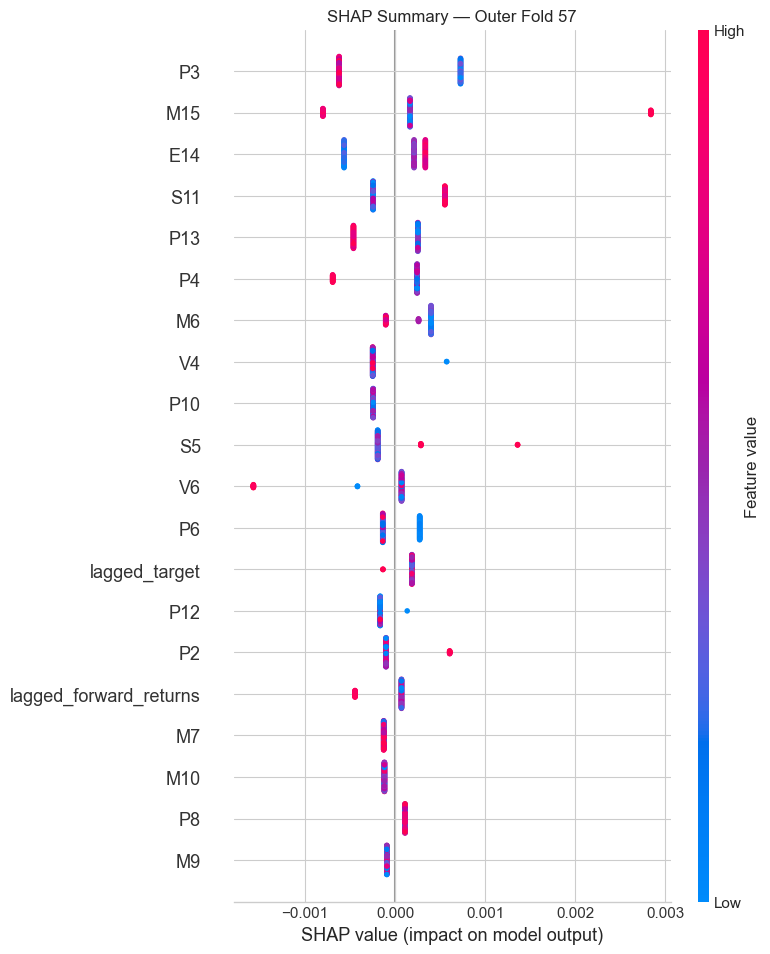

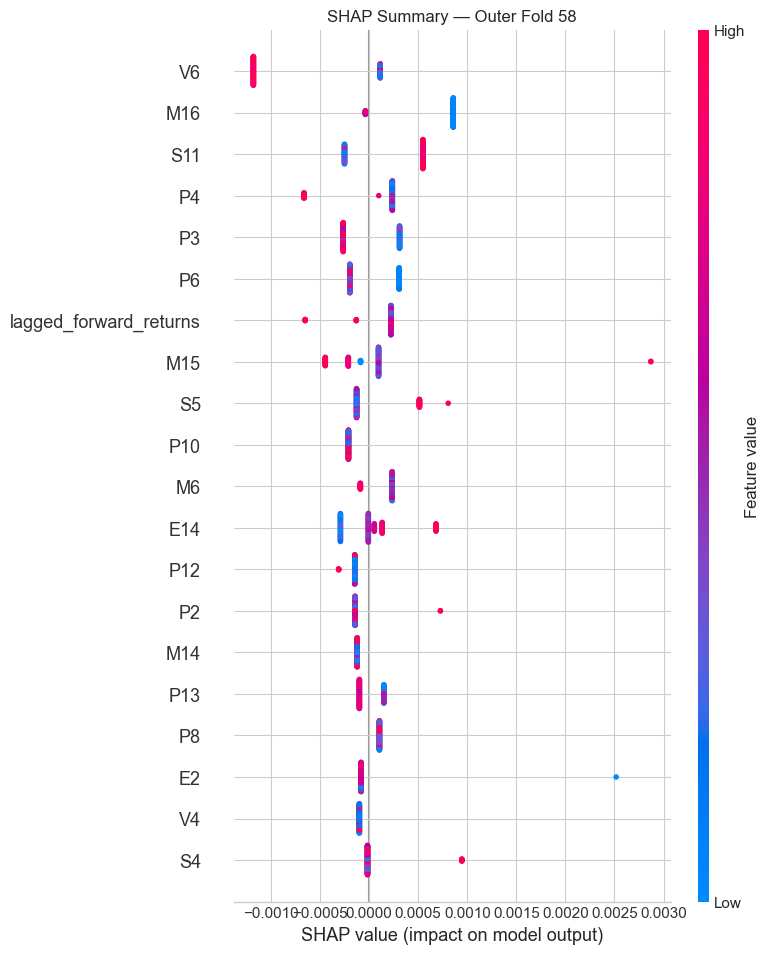

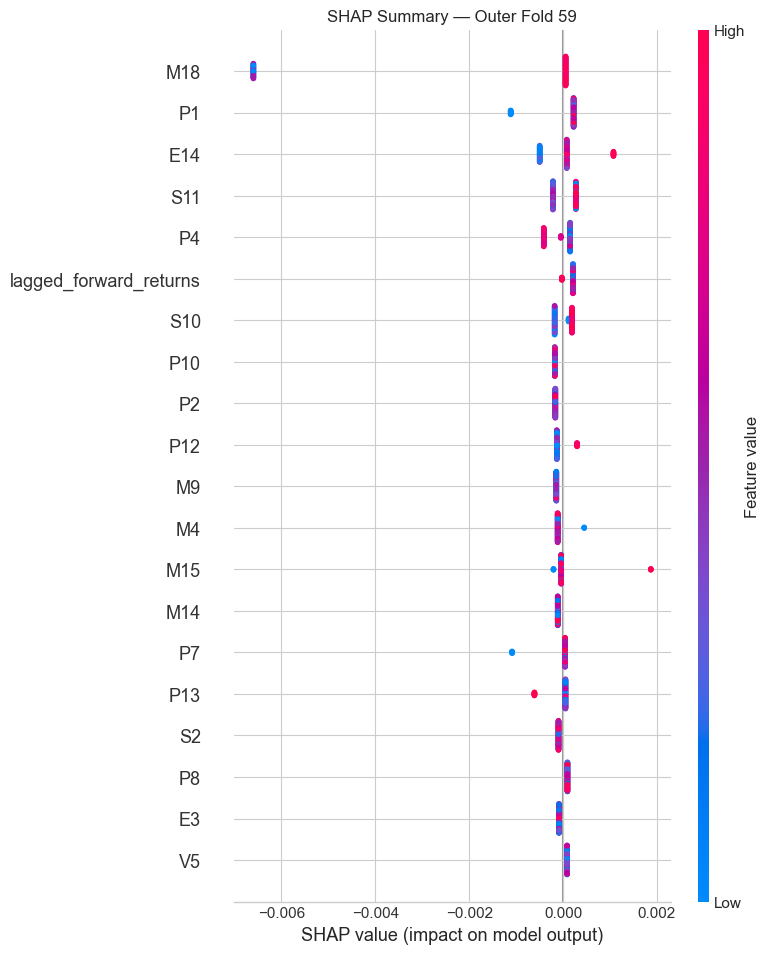

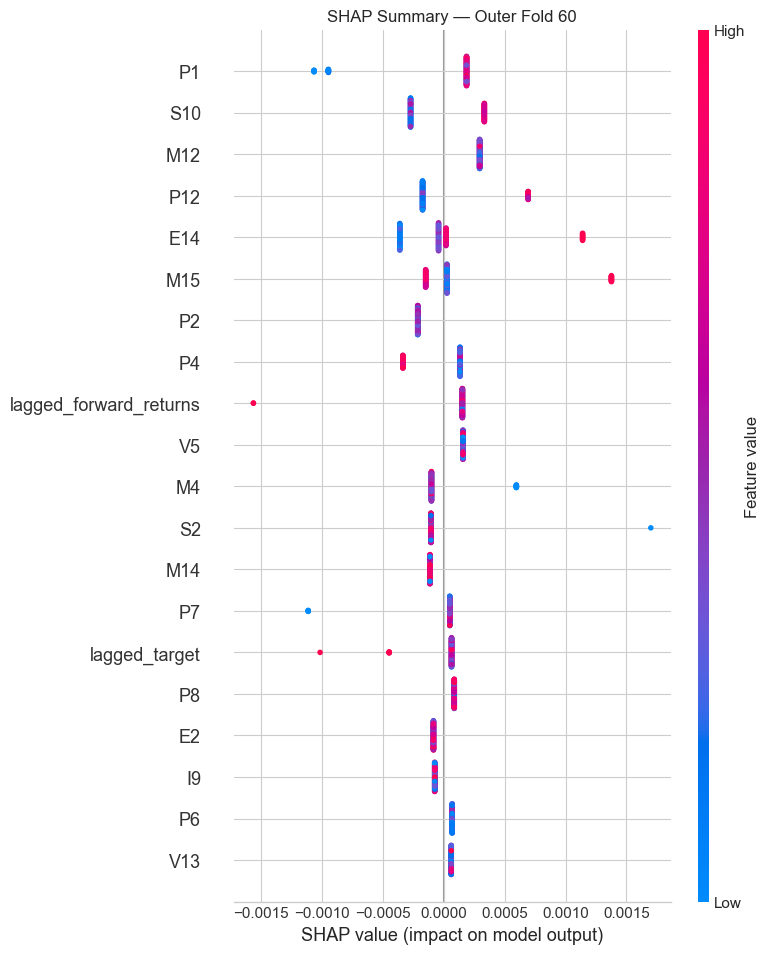

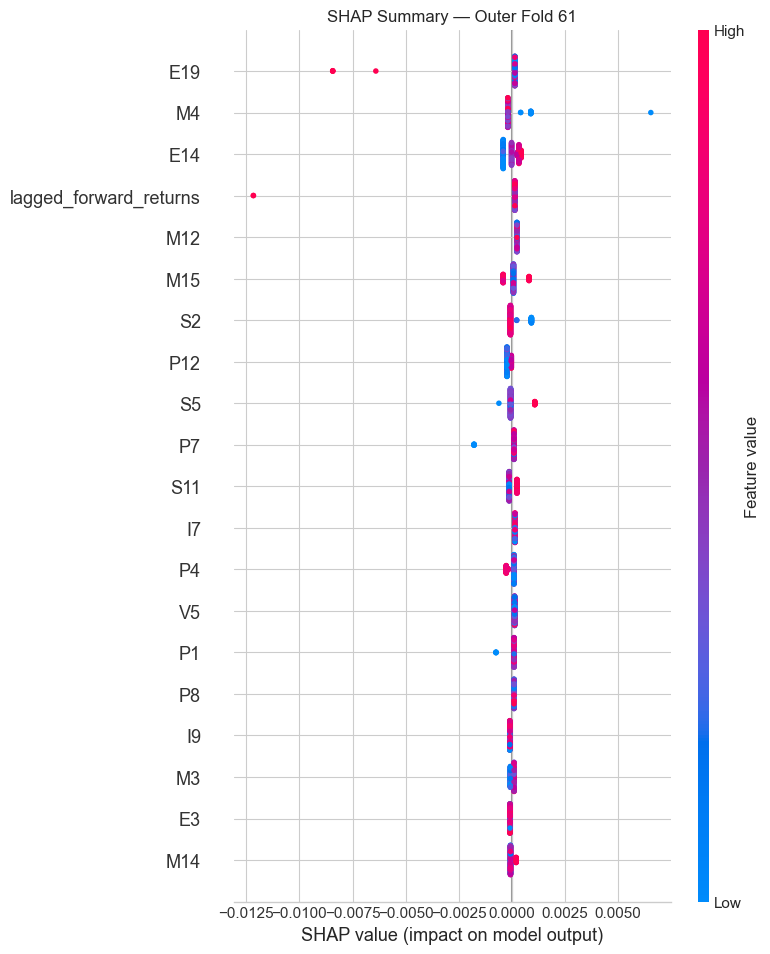

In [12]:
import shap

for i, (model_outer, X_test_outer) in enumerate(zip(results['outer_models'], results['outer_X_tests'])):
    explainer = shap.TreeExplainer(model_outer)
    shap_values = explainer.shap_values(X_test_outer)
    shap.summary_plot(shap_values, X_test_outer, show=False)
    plt.title(f"SHAP Summary — Outer Fold {i+1}")
    plt.show()

In [18]:
all_mean_abs = []
all_mean_signed = []

for model_outer, X_test_outer in zip(results['outer_models'], results['outer_X_tests']):
    explainer = shap.TreeExplainer(model_outer)
    shap_values = explainer.shap_values(X_test_outer)
    
    # mean absolute and mean signed SHAP per feature for this fold
    all_mean_abs.append(np.abs(shap_values).mean(axis=0))
    all_mean_signed.append(shap_values.mean(axis=0))

# Aggregate across folds
mean_abs_shap = np.mean(all_mean_abs, axis=0)
mean_signed_shap = np.mean(all_mean_signed, axis=0)

# Combine into a single DataFrame
direction_df = pd.DataFrame({
    'feature': X_test_outer.columns,
    'mean_abs_shap': mean_abs_shap,
    'mean_signed_shap': mean_signed_shap
})

# Add direction label
direction_df['direction'] = np.where(direction_df['mean_signed_shap'] > 0, 'Positive', 'Negative')

# Sort by importance
direction_df = direction_df.sort_values('mean_abs_shap', ascending=False)

In [19]:
direction_df

,feature,mean_abs_shap,mean_signed_shap,direction
48,P10,5.256003e-04,3.427558e-04,Positive
17,M9,5.245382e-04,-9.120947e-05,Negative
12,M4,4.435032e-04,5.845692e-06,Positive
45,I8,3.163897e-04,-5.134696e-05,Negative
49,P11,2.520777e-04,3.034016e-05,Positive
...,...,...,...,...
93,D9,2.187523e-06,2.271962e-14,Positive
87,D3,1.692202e-06,-3.471919e-08,Negative
89,D5,1.210233e-06,3.065731e-08,Positive
62,V11,7.347963e-07,3.909927e-08,Positive
